Things worth knowing about the data

Set A: 67 stores, 297 articles and 599 store×article pairs. Every pair has all 165 weeks (2021-04-12 to 2024-06-03).
- 43% of rows have 0 units sold. The in-stock rate rises from about 65% to 100% over the period.
- Weekly totals have sharp spikes around Nov–Dec each year.
- stock_snapshot covers a single week (2024-04-08), and most of its columns are all zero.

Set B: this set is synthetic. It covers 2025-01-01 to 2025-11-01, with 5 stores, 5,000 customers, 168k baskets and 1,500 articles.
- Baskets are spread almost exactly evenly across hours of the day, and exactly 6 promotions are active on every day. That's a sign the data was generated, so be careful drawing real-world patterns from it.
- 33% of baskets include a promotion.

Two problems in Set B:
- In b_stock, store_id is text ("S0001") while every other table uses numbers (1), so it won't join until you convert it.
- b_stock has 1,998 article IDs, and 500 of them are missing from b_articles.

In [31]:
# =====================================================================================
# SET A: SUMMARY OF FINDINGS
# =====================================================================================
#
# DATA STRUCTURE
# - 3 tables, joined on (store_id, article_id):
#   * weekly          98,835 rows = 599 store-article pairs x 165 weeks
#                     (2021-04-12 to 2024-06-03). Full grid: weeks with no sales are
#                     included as units=0. Sales history, used for forecasting.
#   * articles        599 rows, one per pair. Product hierarchy (nested codes):
#                     department_group (6) > department (26) > division (47)
#                     > product_group (111) > article_id (297),
#                     e.g. product group 301202 -> division 3012 -> department 30.
#                     Plus store attributes.
#   * stock_snapshot  599 rows, single week 2024-04-08. Only on_hand_end (stock now,
#                     mean ~3.7) and in_transit_2w (arriving in 2 weeks, non-zero for
#                     ~71% of pairs) are filled; the other columns are all 0. Looks like
#                     the starting state for an ordering simulation with a 2-week
#                     delivery time (to confirm with the hackathon brief).
#
# STORES
# - store_format and format are the same attribute coded twice (1=13, 2=216, 5=521,
#   perfect 1:1 mapping). Keep store_format, drop format.
# - Data is very unevenly spread across formats:
#     format 1: 60 stores,  83 pairs (1-3 articles per store)
#     format 2:  5 stores, 513 pairs (86%; 12-224 articles per store)
#     format 5:  2 stores,   3 pairs
#   -> Set A is really 5 large stores (incl. 60, 61, 63) plus many small ones.
#      Plain means mostly reflect format 2. Store 61 alone has 224 articles
#      (~40% of rows) but shows the same seasonal pattern as the others.
#
# DEMAND
# - Low and skewed: mean 2.9 units/week, median 1-2, 43% of rows are 0.
# - in_stock=True with units=0 is real zero demand (keep).
#   in_stock=False means sales were capped by stock (treat as missing, not 0).
# - In-stock rate rises from ~65% to 100% over the period, so early weeks understate
#   true demand.
#
# SEASONALITY (weekly mean by ISO week, checked year by year)
# 1. Christmas (KW50-51): strongest, most consistent peak (KW51 ~8 units every year,
#    vs ~2.5-3 normally). KW52 drops back (25/26 Dec closures). KW1 still elevated
#    (5.2 / 4.3 / 3.8 in 2022-24). Driven mainly by article 23
#    (product group 140402, department 14) in stores 60, 61 and 63.
# 2. November promotion: the peak week starts on the 2nd Monday of November
#    (2021-11-08, 2022-11-14, 2023-11-13, i.e. KW45 in 2021, KW46 in 2022-23),
#    followed by a smaller tail week. ~2.5x a normal week across the chain (median
#    doubles 1 -> 2). Fixed-date events (Singles' Day, St. Martin, Black Friday) don't
#    fit, so most likely a recurring retailer promotion (no promo data to confirm).
#    Driven mainly by product group 240201 (department 24, articles 124/125):
#    store 61 / article 124 sold 494, 443 and 492 in those weeks (normal ~90),
#    with spikes in stores 60, 63, 64 the same weeks.
# 3. May holidays (KW17-19): moderate lift (~1.2-1.4x), peak week shifts with
#    1 May / Ascension / Mother's Day.
# 4. No visible effect: Easter (KW13-15), summer and autumn school breaks
#    (up to 16 states off in KW31, demand flat ~2.4-2.6). KW24 bump is weak and
#    inconsistent across years (noise).
#
# OUTLIERS
# - Top rows (up to 494 units) are NOT errors: they are the November promotion and
#   Christmas peaks of a few high-volume articles. Don't cap them; model them with
#   promo / holiday flags (promo_nov, promo_nov_tail) instead.
# - 15 rows with robust z-score > 20 (median/MAD within each pair), 12 of them in
#   department 30. Likely slow sellers with sudden bulk orders or errors. Still to
#   check before training.
#
# CAVEATS FOR MODELLING
# - Weekly mean per ISO week pools 3-4 years: KW15-23 include 2024, other weeks don't.
# - 2024 mean looks lower (2.80) only because the data ends in June (no Nov/Dec
#   peaks). Compare years on matching weeks only.
# - Store-normalised index (units / pair mean, median by week) gives every store
#   equal weight; use it to check seasonality isn't just format 2.
# - If evaluation starts at 2024-04-08 (stock_snapshot week), weekly rows after that
#   date may be the test period: exclude them from training to avoid leakage.
#
# OPEN ITEMS
# - Inspect the department 30 outliers.
# - Confirm with the brief: evaluation period, delivery time, and how missed_units
#   vs excess stock are scored.
# =====================================================================================

# Hackathon retail sets — EDA of Set A and Set B
Loads every parquet file in `set-a/` and `set-b/` into its own DataFrame, then profiles structure (rows, columns, dtypes, nulls, cardinality), descriptive statistics, and plots per set.

In [1]:
%pip install -q numpy pandas matplotlib pyarrow

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
from IPython.display import display

pd.set_option('display.max_columns', 50)
pd.set_option('display.width', 200)

# Works whether the kernel starts in the notebook folder or the project root
BASE = Path('.') if Path('set-a').exists() else Path('data/hackathon-retail-sets')

# Plot style: recessive grid/axes, thin marks, one hue for single-series charts
BLUE, ORANGE, AQUA, YELLOW, MAGENTA, GREEN, VIOLET, RED = (
    '#2a78d6', '#eb6834', '#1baf7a', '#eda100', '#e87ba4', '#008300', '#6250d6', '#e34948')
CAT = [BLUE, ORANGE, AQUA, YELLOW, MAGENTA, GREEN, VIOLET, RED]  # fixed categorical order
plt.rcParams.update({
    'figure.figsize': (11, 4), 'figure.dpi': 100,
    'axes.spines.top': False, 'axes.spines.right': False,
    'axes.edgecolor': '#b5b4ae', 'axes.labelcolor': '#52514e',
    'xtick.color': '#52514e', 'ytick.color': '#52514e',
    'axes.grid': True, 'grid.color': '#e6e5e0', 'grid.linewidth': 0.8, 'axes.axisbelow': True,
    'axes.titlesize': 12, 'axes.titleweight': 'bold', 'axes.titlelocation': 'left',
    'lines.linewidth': 2, 'axes.prop_cycle': plt.cycler(color=CAT),
})

## 1. Load every file into its own DataFrame

In [3]:
def load_set(folder):
    return {p.stem: pd.read_parquet(p) for p in sorted((BASE / folder).glob('*.parquet'))}

set_a = load_set('set-a')
set_b = load_set('set-b')

# Individual DataFrames
a_articles       = set_a['articles']
a_stock_snapshot = set_a['stock_snapshot']
a_weekly         = set_a['weekly']

b_articles           = set_b['articles']
b_baskets            = set_b['baskets']
b_basket_promotions  = set_b['basket_promotions']
b_promotions         = set_b['promotions']
b_promotion_articles = set_b['promotion_articles']
b_promotion_stores   = set_b['promotion_stores']
b_sales_lines        = set_b['sales_lines']
b_stock              = set_b['stock']
b_stock_events       = set_b['stock_events']

print('Set A:', list(set_a))
print('Set B:', list(set_b))

Set A: ['articles', 'stock_snapshot', 'weekly']
Set B: ['articles', 'basket_promotions', 'baskets', 'promotion_articles', 'promotion_stores', 'promotions', 'sales_lines', 'stock', 'stock_events']


### Parse date / time columns
Dates are stored as strings in the parquet files; convert them so ranges and time plots work.

In [4]:
for df, cols in [
    (a_stock_snapshot, ['week_start']), (a_weekly, ['week_start']),
    (b_baskets, ['timestamp']), (b_stock_events, ['timestamp']),
    (b_promotions, ['start_date', 'end_date']),
]:
    for c in cols:
        df[c] = pd.to_datetime(df[c])

## 2. Overview — size of every table

In [5]:
def overview(sets):
    rows = []
    for set_name, tables in sets.items():
        for name, df in tables.items():
            rows.append({
                'set': set_name, 'table': name,
                'rows': len(df), 'columns': df.shape[1],
                'memory_MB': round(df.memory_usage(deep=True).sum() / 1e6, 2),
                'missing_cells': int(df.isna().sum().sum()),
                'missing_%': round(100 * df.isna().sum().sum() / df.size, 2),
                'duplicate_rows': int(df.duplicated().sum()),
                'column_names': ', '.join(df.columns),
            })
    return pd.DataFrame(rows)

ov = overview({'A': set_a, 'B': set_b})
display(ov)

,set,table,rows,columns,memory_MB,missing_cells,missing_%,duplicate_rows,column_names
0,A,articles,599,8,0.04,0,0.00,0,"store_id, article_id, product_group, division,..."
1,A,stock_snapshot,599,9,0.04,0,0.00,0,"store_id, article_id, week_start, on_hand_star..."
2,A,weekly,98835,5,3.26,0,0.00,0,"store_id, article_id, week_start, units, in_stock"
3,B,articles,1500,6,0.11,0,0.00,0,"article_id, category, subcategory, unit_size, ..."
4,B,basket_promotions,68573,5,5.71,0,0.00,0,"transaction_id, line_no, promotion_id, mechani..."
5,B,baskets,167823,10,19.70,0,0.00,0,"transaction_id, customer_id, store_id, timesta..."
6,B,promotion_articles,3099,2,0.12,0,0.00,0,"promotion_id, article_id"
7,B,promotion_stores,149,2,0.01,0,0.00,0,"promotion_id, store_id"
8,B,promotions,264,13,0.03,1040,30.30,0,"bundle_qty, buy_qty, can_stack, category, end_..."
9,B,sales_lines,504000,8,44.35,0,0.00,0,"transaction_id, line_no, article_id, units, un..."


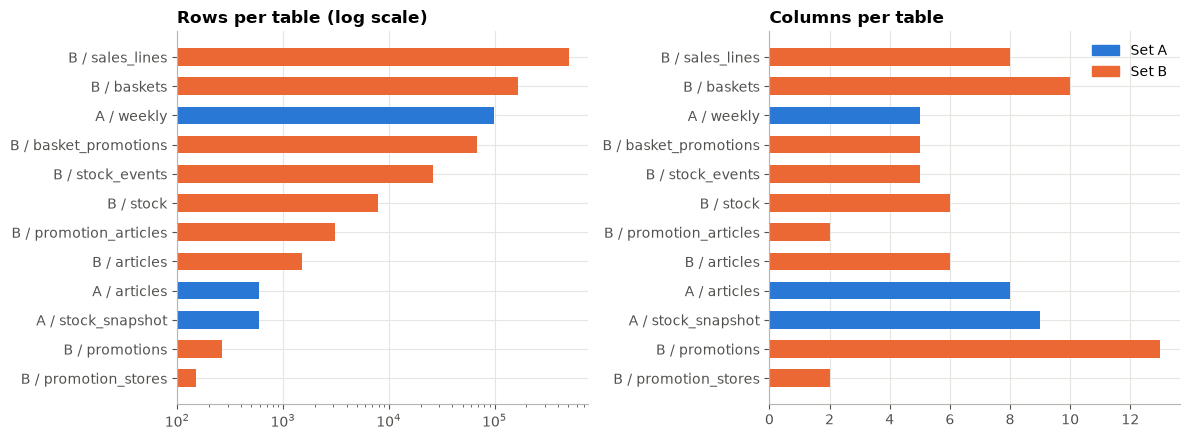

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
o = ov.assign(label=ov['set'] + ' / ' + ov['table']).sort_values('rows')
colors = [BLUE if s == 'A' else ORANGE for s in o['set']]
axes[0].barh(o['label'], o['rows'], color=colors, height=0.6)
axes[0].set_xscale('log'); axes[0].set_title('Rows per table (log scale)')
axes[1].barh(o['label'], o['columns'], color=colors, height=0.6)
axes[1].set_title('Columns per table')
from matplotlib.patches import Patch
axes[1].legend(handles=[Patch(color=BLUE, label='Set A'), Patch(color=ORANGE, label='Set B')], frameon=False)
plt.tight_layout(); plt.show()

## 3. Column-level profile
For every column: dtype, non-null count, % missing, distinct values, min / max and example values.

In [7]:
def profile(df):
    out = []
    for c in df.columns:
        s = df[c]
        is_num = pd.api.types.is_numeric_dtype(s) and not pd.api.types.is_bool_dtype(s)
        is_dt = pd.api.types.is_datetime64_any_dtype(s)
        out.append({
            'column': c, 'dtype': str(s.dtype),
            'non_null': int(s.notna().sum()),
            'missing_%': round(100 * s.isna().mean(), 2),
            'n_unique': int(s.nunique()),
            'unique_%': round(100 * s.nunique() / max(len(s), 1), 2),
            'min': s.min() if (is_num or is_dt) else None,
            'max': s.max() if (is_num or is_dt) else None,
            'mean': round(s.mean(), 3) if is_num else None,
            'zeros_%': round(100 * (s == 0).mean(), 2) if is_num else None,
            'examples': ', '.join(map(str, s.dropna().unique()[:5])),
        })
    return pd.DataFrame(out)

for set_name, tables in [('A', set_a), ('B', set_b)]:
    for name, df in tables.items():
        print(f'\n=== Set {set_name} / {name}  —  {df.shape[0]:,} rows × {df.shape[1]} cols ===')
        display(profile(df))


=== Set A / articles  —  599 rows × 8 cols ===


,column,dtype,non_null,missing_%,n_unique,unique_%,min,max,mean,zeros_%,examples
0,store_id,int64,599,0.0,67,11.19,0,66,56.881,0.33,"0, 1, 2, 3, 4"
1,article_id,int64,599,0.0,297,49.58,0,296,137.766,0.17,"126, 182, 124, 49, 103"
2,product_group,int64,599,0.0,111,18.53,20318,590001,309149.321,0.00,"301202, 440403, 240201, 40215, 440402"
3,division,int64,599,0.0,47,7.85,203,5900,3091.442,0.00,"3012, 4404, 2402, 402, 2003"
4,department,int64,599,0.0,26,4.34,2,59,30.865,0.00,"30, 44, 24, 4, 20"
5,department_group,int64,599,0.0,6,1.00,1,12,9.002,0.00,"11, 5, 9, 3, 12"
6,store_format,int64,599,0.0,3,0.50,1,5,1.876,0.00,"1, 2, 5"
7,format,int64,599,0.0,3,0.50,13,521,189.399,0.00,"13, 216, 521"



=== Set A / stock_snapshot  —  599 rows × 9 cols ===


,column,dtype,non_null,missing_%,n_unique,unique_%,min,max,mean,zeros_%,examples
0,store_id,int64,599,0.0,67,11.19,0,66,56.881,0.33,"0, 1, 2, 3, 4"
1,article_id,int64,599,0.0,297,49.58,0,296,137.766,0.17,"126, 182, 124, 49, 103"
2,week_start,datetime64[s],599,0.0,1,0.17,2024-04-08 00:00:00,2024-04-08 00:00:00,NaN,NaN,2024-04-08 00:00:00
3,on_hand_start,int64,599,0.0,1,0.17,0,0,0.000,100.00,0
4,units,int64,599,0.0,1,0.17,0,0,0.000,100.00,0
5,missed_units,int64,599,0.0,1,0.17,0,0,0.000,100.00,0
6,on_hand_end,int64,599,0.0,30,5.01,1,100,3.715,0.00,"3, 1, 6, 9, 4"
7,in_transit_1w,int64,599,0.0,1,0.17,0,0,0.000,100.00,0
8,in_transit_2w,int64,599,0.0,29,4.84,0,99,2.836,29.38,"3, 1, 6, 7, 2"



=== Set A / weekly  —  98,835 rows × 5 cols ===


,column,dtype,non_null,missing_%,n_unique,unique_%,min,max,mean,zeros_%,examples
0,store_id,int64,98835,0.0,67,0.07,0,66,56.881,0.33,"0, 1, 2, 3, 4"
1,article_id,int64,98835,0.0,297,0.30,0,296,137.766,0.17,"126, 182, 124, 49, 103"
2,week_start,datetime64[s],98835,0.0,165,0.17,2021-04-12 00:00:00,2024-06-03 00:00:00,NaN,NaN,"2021-04-12 00:00:00, 2021-04-19 00:00:00, 2021..."
3,units,float64,98835,0.0,201,0.20,0.0,494.0,2.940,43.16,"0.0, 3.0, 1.0, 5.0, 4.0"
4,in_stock,bool,98835,0.0,2,0.00,None,None,NaN,NaN,"True, False"


... (14 outputs left out)


=== Set B / stock  —  7,970 rows × 6 cols ===


,column,dtype,non_null,missing_%,n_unique,unique_%,min,max,mean,zeros_%,examples
0,article_id,str,7970,0.00,1998,25.07,NaN,NaN,NaN,NaN,"P00470, P01980, P01066, P01535, P01370"
1,store_id,str,7970,0.00,5,0.06,NaN,NaN,NaN,NaN,"S0001, S0002, S0003, S0004, S0005"
2,on_hand,int64,7970,0.00,91,1.14,10.0,100.0,55.399,0.0,"84, 23, 70, 14, 64"
3,reorder_point,int64,7970,0.00,21,0.26,10.0,30.0,20.032,0.0,"24, 11, 14, 20, 17"
4,price_override_cents,float64,2794,64.94,1178,14.78,149.0,1875.0,776.968,0.0,"768.0, 1173.0, 317.0, 678.0, 1577.0"
5,active,bool,7970,0.00,1,0.01,NaN,NaN,NaN,NaN,True



=== Set B / stock_events  —  26,215 rows × 5 cols ===


,column,dtype,non_null,missing_%,n_unique,unique_%,min,max,mean,zeros_%,examples
0,timestamp,datetime64[us],26215,0.0,272,1.04,2025-01-01 07:30:00,2025-11-01 22:00:00,NaN,NaN,"2025-01-01 08:00:00, 2025-01-01 22:00:00, 2025..."
1,store_id,int64,26215,0.0,5,0.02,1,5,3.190,0.00,"1, 2, 3, 4, 5"
2,article_id,str,26215,0.0,1500,5.72,None,None,NaN,NaN,"P00309, P01334, P00149, P00749, P00119"
3,delta,int64,26215,0.0,72,0.27,0,100,61.805,6.01,"0, 89, 82, 88, 62"
4,reason,str,26215,0.0,2,0.01,None,None,NaN,NaN,"STOCKOUT, REPLENISH"


## 4. Descriptive statistics (`describe`)

In [8]:
for set_name, tables in [('A', set_a), ('B', set_b)]:
    for name, df in tables.items():
        print(f'\n=== Set {set_name} / {name} ===')
        display(df.describe(include='all').T)


=== Set A / articles ===


,count,mean,std,min,25%,50%,75%,max
store_id,599.0,56.881469,12.868033,0.0,60.0,61.0,62.0,66.0
article_id,599.0,137.766277,83.772379,0.0,68.5,126.0,208.5,296.0
product_group,599.0,309149.320534,144830.725627,20318.0,200606.0,301202.0,401001.0,590001.0
division,599.0,3091.442404,1448.320031,203.0,2006.0,3012.0,4010.0,5900.0
department,599.0,30.864775,14.479373,2.0,20.0,30.0,40.0,59.0
department_group,599.0,9.001669,2.702346,1.0,9.0,9.0,11.0,12.0
store_format,599.0,1.876461,0.410681,1.0,2.0,2.0,2.0,5.0
format,599.0,189.398998,74.010322,13.0,216.0,216.0,216.0,521.0



=== Set A / stock_snapshot ===


,count,mean,min,25%,50%,75%,max,std
store_id,599.0,56.881469,0.0,60.0,61.0,62.0,66.0,12.868033
article_id,599.0,137.766277,0.0,68.5,126.0,208.5,296.0,83.772379
week_start,599,2024-04-08 00:00:00,2024-04-08 00:00:00,2024-04-08 00:00:00,2024-04-08 00:00:00,2024-04-08 00:00:00,2024-04-08 00:00:00,NaN
on_hand_start,599.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
units,599.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
missed_units,599.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
on_hand_end,599.0,3.714524,1.0,1.0,2.0,3.0,100.0,9.139772
in_transit_1w,599.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
in_transit_2w,599.0,2.836394,0.0,0.0,1.0,2.0,99.0,9.169891



=== Set A / weekly ===


,count,unique,top,freq,mean,min,25%,50%,75%,max,std
store_id,98835.0,NaN,NaN,NaN,56.881469,0.0,60.0,61.0,62.0,66.0,12.857352
article_id,98835.0,NaN,NaN,NaN,137.766277,0.0,68.0,126.0,209.0,296.0,83.702846
week_start,98835,NaN,NaN,NaN,2022-11-07 00:00:00,2021-04-12 00:00:00,2022-01-24 00:00:00,2022-11-07 00:00:00,2023-08-21 00:00:00,2024-06-03 00:00:00,NaN
units,98835.0,NaN,NaN,NaN,2.940436,0.0,0.0,1.0,2.0,494.0,10.367506
in_stock,98835,2,True,88318,NaN,NaN,NaN,NaN,NaN,NaN,NaN


... (14 outputs left out)


=== Set B / stock ===


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
article_id,7970,1998,P01980,5,NaN,NaN,NaN,NaN,NaN,NaN,NaN
store_id,7970,5,S0001,1807,NaN,NaN,NaN,NaN,NaN,NaN,NaN
on_hand,7970.0,NaN,NaN,NaN,55.398996,26.425539,10.0,33.0,55.0,79.0,100.0
reorder_point,7970.0,NaN,NaN,NaN,20.032371,6.036257,10.0,15.0,20.0,25.0,30.0
price_override_cents,2794.0,NaN,NaN,NaN,776.967788,460.075418,149.0,418.0,587.5,1092.75,1875.0
active,7970,1,True,7970,NaN,NaN,NaN,NaN,NaN,NaN,NaN



=== Set B / stock_events ===


,count,unique,top,freq,mean,min,25%,50%,75%,max,std
timestamp,26215,NaN,NaN,NaN,2025-03-09 05:06:16.959756,2025-01-01 07:30:00,2025-01-01 07:30:00,2025-01-01 22:00:00,2025-05-18 22:00:00,2025-11-01 22:00:00,NaN
store_id,26215.0,NaN,NaN,NaN,3.189662,1.0,2.0,3.0,4.0,5.0,1.407711
article_id,26215,1500,P00701,23,NaN,NaN,NaN,NaN,NaN,NaN,NaN
delta,26215.0,NaN,NaN,NaN,61.805379,0.0,50.0,61.0,81.0,100.0,24.256536
reason,26215,2,REPLENISH,24639,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## 5. Key relationships / consistency checks
How the tables join, and whether the IDs line up.

In [9]:
def coverage(left, right, key, lname, rname):
    l, r = set(left[key].dropna().astype(str)), set(right[key].dropna().astype(str))
    return {'check': f'{lname}.{key} ⊆ {rname}.{key}', f'distinct_in_left': len(l),
            'missing_from_right': len(l - r), 'pct_covered': round(100 * len(l & r) / max(len(l), 1), 1)}

checks = pd.DataFrame([
    coverage(a_weekly, a_articles, 'article_id', 'A.weekly', 'A.articles'),
    coverage(a_weekly, a_articles, 'store_id', 'A.weekly', 'A.articles'),
    coverage(a_stock_snapshot, a_articles, 'article_id', 'A.stock_snapshot', 'A.articles'),
    coverage(b_sales_lines, b_articles, 'article_id', 'B.sales_lines', 'B.articles'),
    coverage(b_sales_lines, b_baskets, 'transaction_id', 'B.sales_lines', 'B.baskets'),
    coverage(b_basket_promotions, b_promotions, 'promotion_id', 'B.basket_promotions', 'B.promotions'),
    coverage(b_promotion_articles, b_articles, 'article_id', 'B.promotion_articles', 'B.articles'),
    coverage(b_stock, b_articles, 'article_id', 'B.stock', 'B.articles'),
    coverage(b_stock_events, b_articles, 'article_id', 'B.stock_events', 'B.articles'),
])
display(checks)

print('Set A: store × article pairs in articles:', len(a_articles),
      '| in weekly:', a_weekly[['store_id', 'article_id']].drop_duplicates().shape[0])
print('Set A: weeks per store×article:', a_weekly.groupby(['store_id', 'article_id']).size().describe().to_dict())
print('Set B: store_id values  baskets:', sorted(b_baskets.store_id.unique()),
      '| stock:', sorted(b_stock.store_id.unique()), ' <- different format (str vs int)')

,check,distinct_in_left,missing_from_right,pct_covered
0,A.weekly.article_id ⊆ A.articles.article_id,297,0,100.0
1,A.weekly.store_id ⊆ A.articles.store_id,67,0,100.0
2,A.stock_snapshot.article_id ⊆ A.articles.artic...,297,0,100.0
3,B.sales_lines.article_id ⊆ B.articles.article_id,1500,0,100.0
4,B.sales_lines.transaction_id ⊆ B.baskets.trans...,167823,0,100.0
5,B.basket_promotions.promotion_id ⊆ B.promotion...,264,0,100.0
6,B.promotion_articles.article_id ⊆ B.articles.a...,1306,0,100.0
7,B.stock.article_id ⊆ B.articles.article_id,1998,500,75.0
8,B.stock_events.article_id ⊆ B.articles.article_id,1500,0,100.0


Set A: store × article pairs in articles: 599 | in weekly: 599
Set A: weeks per store×article: {'count': 599.0, 'mean': 165.0, 'std': 0.0, 'min': 165.0, '25%': 165.0, '50%': 165.0, '75%': 165.0, 'max': 165.0}
Set B: store_id values  baskets: [np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5)] | stock: ['S0001', 'S0002', 'S0003', 'S0004', 'S0005']  <- different format (str vs int)


## 6. Set A — plots
Weekly units sold per store × article (2021-04 → 2024-04), plus hierarchy codes and a one-week stock snapshot.

In [10]:
print('Date range:', a_weekly.week_start.min().date(), '→', a_weekly.week_start.max().date(),
      f'({a_weekly.week_start.nunique()} weeks)')
print('Stores:', a_weekly.store_id.nunique(), '| Articles:', a_weekly.article_id.nunique())
print(f"Share of rows with 0 units: {100*(a_weekly.units == 0).mean():.1f}%")
print(f"Share of rows in stock:     {100*a_weekly.in_stock.mean():.1f}%")
print(f"Missing units:              {a_weekly.units.isna().sum()}")

Date range: 2021-04-12 → 2024-06-03 (165 weeks)
Stores: 67 | Articles: 297
Share of rows with 0 units: 43.2%
Share of rows in stock:     89.4%
Missing units:              0


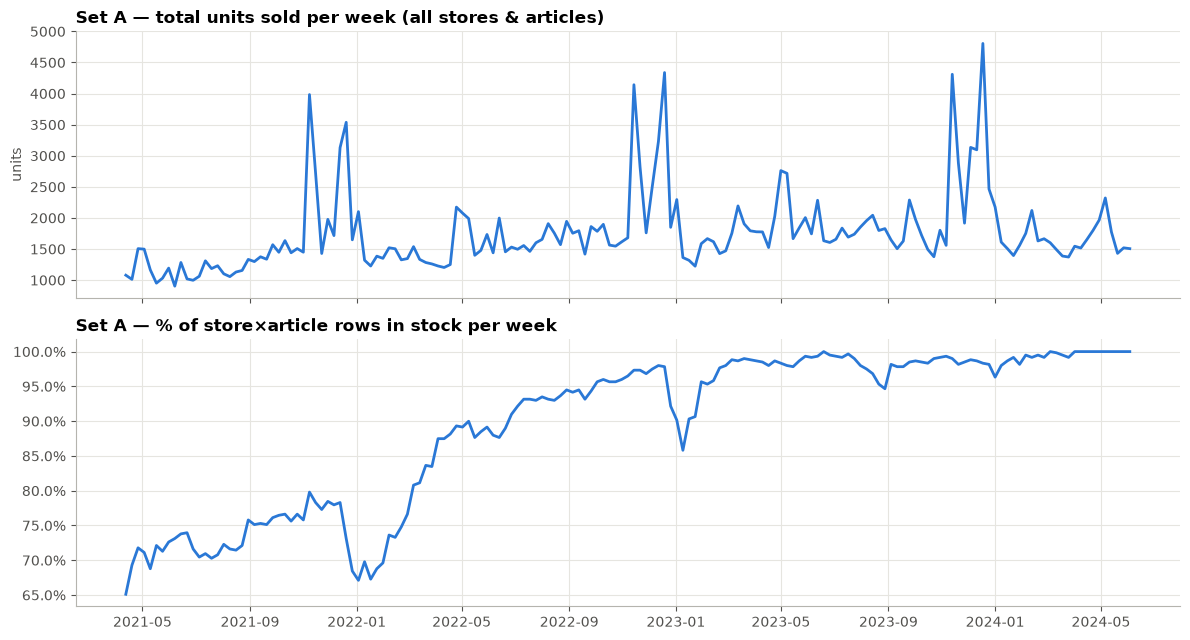

In [11]:
wk = a_weekly.groupby('week_start').agg(units=('units', 'sum'), in_stock=('in_stock', 'mean'))
fig, axes = plt.subplots(2, 1, figsize=(12, 6.5), sharex=True)
axes[0].plot(wk.index, wk['units'], color=BLUE)
axes[0].set_title('Set A — total units sold per week (all stores & articles)')
axes[0].set_ylabel('units')
axes[1].plot(wk.index, wk['in_stock'] * 100, color=BLUE)
axes[1].set_title('Set A — % of store×article rows in stock per week')
axes[1].yaxis.set_major_formatter(mtick.PercentFormatter())
plt.tight_layout(); plt.show()

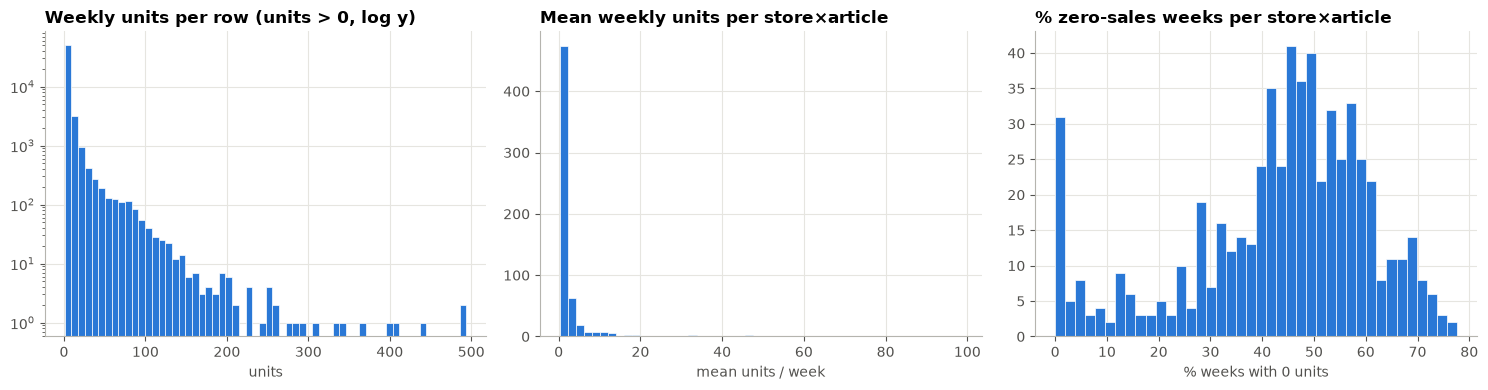

In [12]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
u = a_weekly['units'].dropna()
axes[0].hist(u[u > 0], bins=60, color=BLUE, edgecolor='white', linewidth=0.5)
axes[0].set_yscale('log'); axes[0].set_title('Weekly units per row (units > 0, log y)')
axes[0].set_xlabel('units')

per_series = a_weekly.groupby(['store_id', 'article_id'])['units'].mean()
axes[1].hist(per_series, bins=50, color=BLUE, edgecolor='white', linewidth=0.5)
axes[1].set_title('Mean weekly units per store×article'); axes[1].set_xlabel('mean units / week')

zero_share = a_weekly.groupby(['store_id', 'article_id'])['units'].apply(lambda s: (s == 0).mean() * 100)
axes[2].hist(zero_share, bins=40, color=BLUE, edgecolor='white', linewidth=0.5)
axes[2].set_title('% zero-sales weeks per store×article'); axes[2].set_xlabel('% weeks with 0 units')
plt.tight_layout(); plt.show()

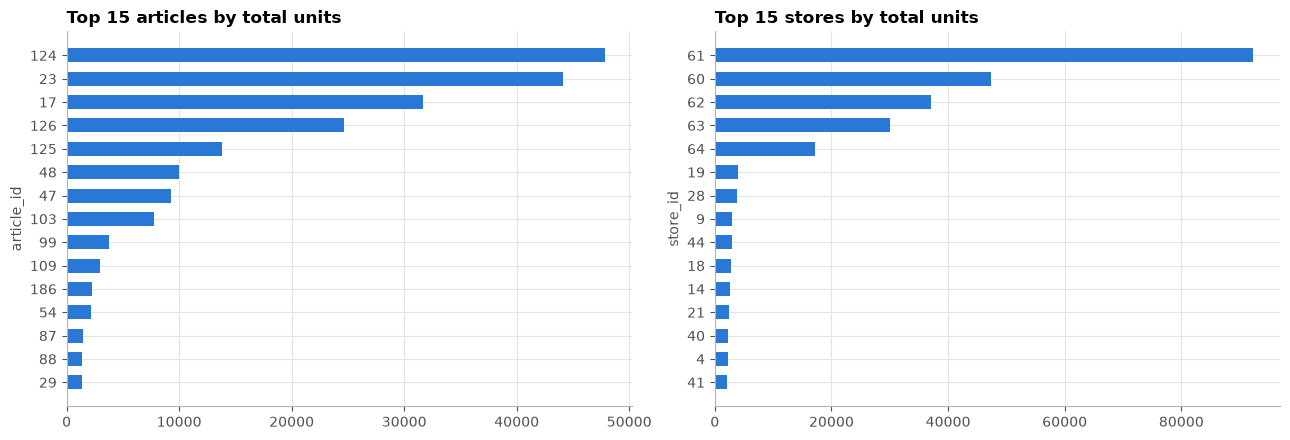

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
top_art = a_weekly.groupby('article_id')['units'].sum().nlargest(15).sort_values()
axes[0].barh(top_art.index.astype(str), top_art.values, color=BLUE, height=0.6)
axes[0].set_title('Top 15 articles by total units'); axes[0].set_ylabel('article_id')
top_store = a_weekly.groupby('store_id')['units'].sum().nlargest(15).sort_values()
axes[1].barh(top_store.index.astype(str), top_store.values, color=BLUE, height=0.6)
axes[1].set_title('Top 15 stores by total units'); axes[1].set_ylabel('store_id')
plt.tight_layout(); plt.show()

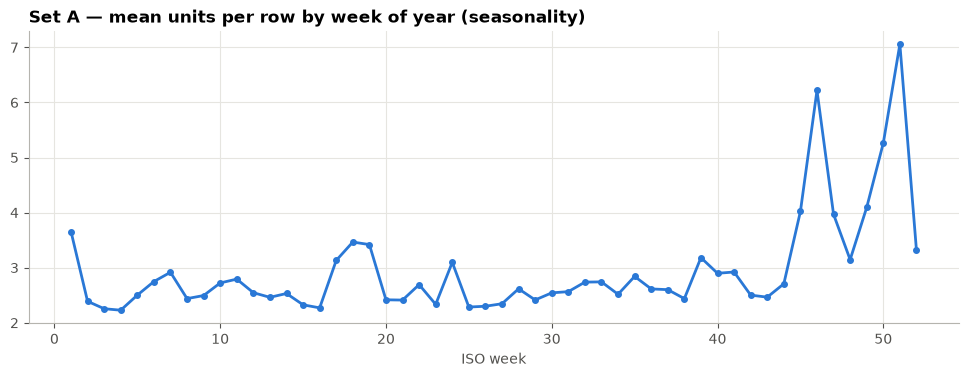

In [14]:
# Seasonality: average units by ISO week-of-year
woy = a_weekly.assign(woy=a_weekly.week_start.dt.isocalendar().week.astype(int)).groupby('woy')['units'].mean()
fig, ax = plt.subplots(figsize=(12, 3.8))
ax.plot(woy.index, woy.values, color=BLUE, marker='o', markersize=4)
ax.set_title('Set A — mean units per row by week of year (seasonality)'); ax.set_xlabel('ISO week')
plt.show()

In [15]:
a = a_weekly.assign(
    woy=a_weekly.week_start.dt.isocalendar().week.astype(int),
    year=a_weekly.week_start.dt.isocalendar().year.astype(int),
)
a_in = a[a.in_stock]  # drop stockout rows

# 1. Does each bump happen every year, or is it one outlier year?
by_year = a_in.pivot_table(index='woy', columns='year', values='units', aggfunc='mean')
print(by_year.loc[[1, 17, 18, 19, 24, 45, 46, 47, 50, 51, 52]])

# 2. Mean vs median, and how many rows each week is based on
print(a_in.groupby('woy')['units'].agg(['mean', 'median', 'count']).loc[44:48])

# 3. Which stores drive KW 46?
print(a_in[a_in.woy == 46].groupby(['year', 'store_id'])['units'].sum()
      .sort_values(ascending=False).head(10))

# 4. Year-over-year trend (affects weeks averaged over 4 years)
print(a_in.groupby('year')['units'].mean())

year      2021      2022      2023      2024
woy                                         
1          NaN  5.226368  4.250000  3.769497
17    3.502326  4.063551  3.424704  3.005008
18    3.516432  3.891386  4.687606  3.282137
19    2.827670  3.692022  4.628620  3.874791
24    2.902715  3.805714  3.838655       NaN
45    8.334728  2.908304  2.620168       NaN
46    5.799574  7.104631  7.268128       NaN
47    3.084233  4.837050  4.903061       NaN
50    6.675906  5.500852  5.238579       NaN
51    8.077626  7.402730  8.159593       NaN
52    4.019512  3.349638  4.192177       NaN
         mean  median  count
woy                         
44   2.997535     1.0   1623
45   4.375530     1.0   1651
46   6.791489     2.0   1645
47   4.364137     1.0   1634
48   3.446951     1.0   1640
year  store_id
2023  61          1602.0
2022  61          1590.0
2021  61           996.0
2023  63           787.0
2022  60           739.0
2023  60           732.0
2021  60           552.0
2022  63           534

In [16]:
a_in = a_in.copy()
# each store-article's sales relative to its own average week (1.0 = normal)
a_in['idx'] = a_in.units / a_in.groupby(['store_id', 'article_id']).units.transform('mean')
season = a_in.groupby('woy')['idx'].median()   # typical store, not dominated by big ones

# is KW 46 special for store 61, or is 61 just always big?
s61 = a_in[a_in.store_id == 61]
print(s61.groupby('woy').units.mean().loc[[44, 45, 46, 47, 48]], s61.units.mean())

woy
44    2.415157
45    4.262215
46    6.820847
47    4.042693
48    2.868078
Name: units, dtype: float64 2.7826349110642146


In [17]:
# --- Seasonality findings: weekly units per store-article (Apr 2021 - Jun 2024) ---
#
# Method: a_weekly is a full store x article x week grid. Weeks with no sales are
#   included as units=0 (real zero demand). Rows with in_stock=False are excluded,
#   since 0 there means "could not sell", not "did not sell". Each ISO week is the
#   mean over 3-4 years: KW15-23 include 2024, the other weeks don't.
#
# 1. Christmas (KW50-51): strongest and most consistent peak. KW51 is ~8 units
#    every year (normal week ~2.5-3). KW52 drops back (25/26 Dec closures).
#    KW1 stays elevated after Christmas (5.2 / 4.3 / 3.8 in 2022-24).
#
# 2. November promotion (~KW46): ~2.5x a normal week, every year (5.8 / 7.1 / 7.3).
#    The peak week begins on the 2nd Monday of November (KW45 in 2021, KW46 in
#    2022-23), followed by a smaller tail week. Fixed dates (Singles' Day, St. Martin,
#    Black Friday) don't fit, so most likely a recurring retailer promotion
#    (unconfirmed, no promo data). The lift is chain-wide: the median doubles (1 -> 2)
#    and store 61 shows the same ~2.5x lift as all stores combined.
#
# 3. May holidays (KW17-19): moderate lift (~1.2-1.4x). The peak week shifts with
#    1 May, Ascension and Mother's Day.
#
# 4. No visible effect: Easter (KW13-15), summer school breaks (up to 16 states
#    off, flat ~2.4-2.6), autumn breaks. KW24 bump is weak and inconsistent (noise).
#
# Caveats:
# - Store 61 is ~40% of rows (~230/week), so it heavily weights the plain mean.
#   It follows the same pattern, but a store-normalised index (units / store-article
#   mean, median by week) gives every store equal weight.
# - 2024 mean looks lower (2.80) only because the data ends in June (no Nov/Dec
#   peaks). Compare years on matching weeks only.
# - Mean >> median (median 1-2): demand per store-article-week is low and skewed.

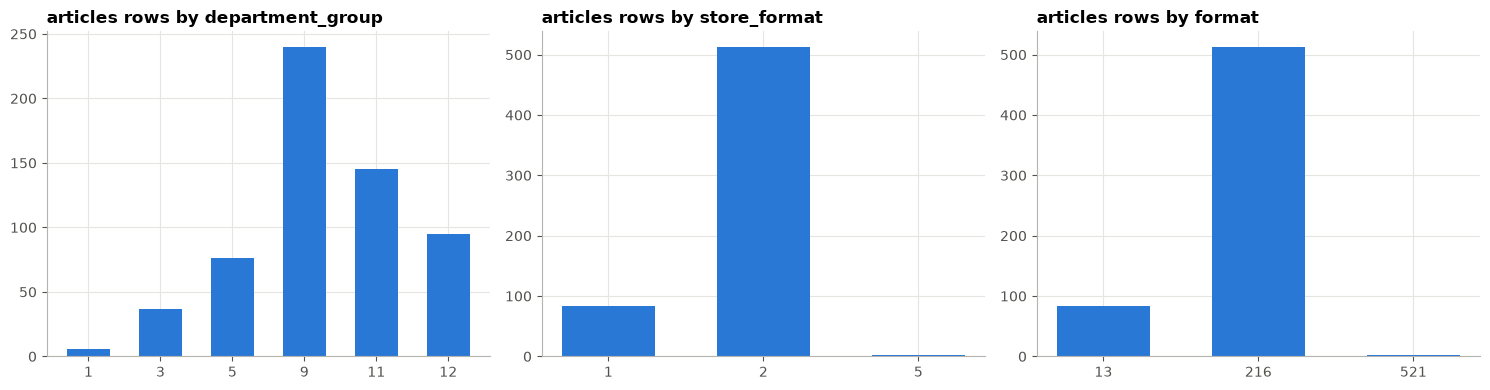

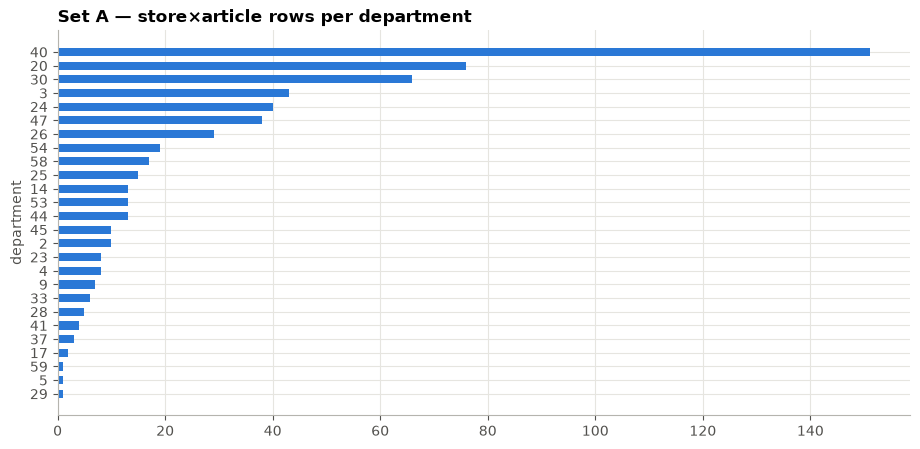

In [18]:
# Hierarchy: how articles distribute over the hierarchy codes
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, ['department_group', 'store_format', 'format']):
    vc = a_articles[col].value_counts().sort_index()
    ax.bar(vc.index.astype(str), vc.values, color=BLUE, width=0.6)
    ax.set_title(f'articles rows by {col}')
plt.tight_layout(); plt.show()

dept = a_articles['department'].value_counts().sort_values()
fig, ax = plt.subplots(figsize=(11, 5))
ax.barh(dept.index.astype(str), dept.values, color=BLUE, height=0.6)
ax.set_title('Set A — store×article rows per department'); ax.set_ylabel('department')
plt.show()

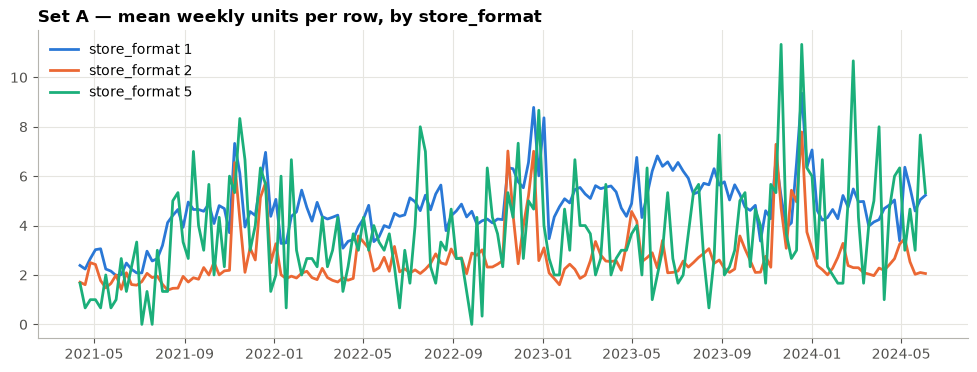

In [19]:
# Units by store_format (join weekly -> articles hierarchy)
aw = a_weekly.merge(a_articles, on=['store_id', 'article_id'], how='left')
fmt = aw.groupby(['week_start', 'store_format'])['units'].mean().unstack()
fig, ax = plt.subplots(figsize=(12, 4))
for i, c in enumerate(fmt.columns):
    ax.plot(fmt.index, fmt[c], color=CAT[i], label=f'store_format {c}')
ax.set_title('Set A — mean weekly units per row, by store_format'); ax.legend(frameon=False)
plt.show()

Snapshot week: <DatetimeArray>
['2024-04-08 00:00:00']
Length: 1, dtype: datetime64[s]


,count,mean,min,25%,50%,75%,max,std
store_id,599.0,56.881469,0.0,60.0,61.0,62.0,66.0,12.868033
article_id,599.0,137.766277,0.0,68.5,126.0,208.5,296.0,83.772379
week_start,599,2024-04-08 00:00:00,2024-04-08 00:00:00,2024-04-08 00:00:00,2024-04-08 00:00:00,2024-04-08 00:00:00,2024-04-08 00:00:00,NaN
on_hand_start,599.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
units,599.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
missed_units,599.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
on_hand_end,599.0,3.714524,1.0,1.0,2.0,3.0,100.0,9.139772
in_transit_1w,599.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
in_transit_2w,599.0,2.836394,0.0,0.0,1.0,2.0,99.0,9.169891


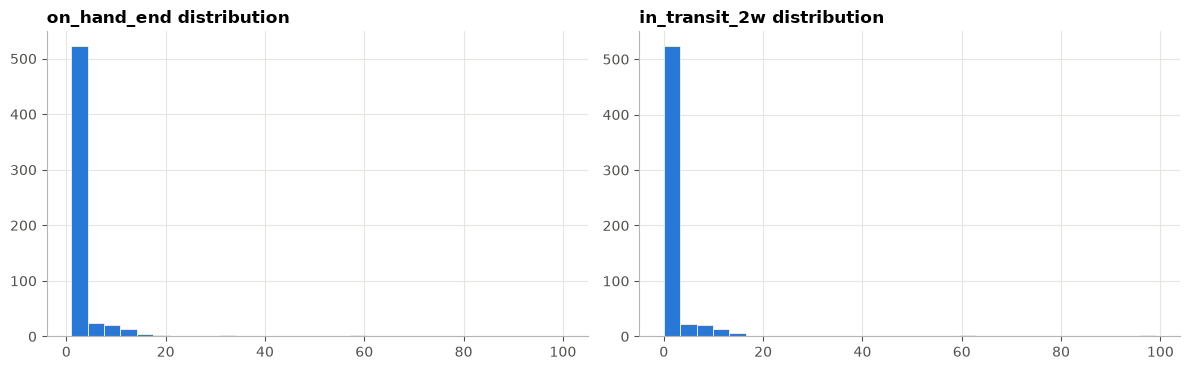

In [20]:
# Stock snapshot (single week)
print('Snapshot week:', a_stock_snapshot.week_start.unique())
display(a_stock_snapshot.describe().T)
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
axes[0].hist(a_stock_snapshot['on_hand_end'], bins=30, color=BLUE, edgecolor='white', linewidth=0.5)
axes[0].set_title('on_hand_end distribution')
axes[1].hist(a_stock_snapshot['in_transit_2w'], bins=30, color=BLUE, edgecolor='white', linewidth=0.5)
axes[1].set_title('in_transit_2w distribution')
plt.tight_layout(); plt.show()

## 7. Set B — plots
Synthetic grocery chain: transaction-level baskets & sales lines, articles, promotions, stock levels and stock events.

In [21]:
print('Basket date range:', b_baskets.timestamp.min(), '→', b_baskets.timestamp.max())
print('Stores:', b_baskets.store_id.nunique(), '| Customers:', b_baskets.customer_id.nunique(),
      '| Transactions:', len(b_baskets), '| Articles sold:', b_sales_lines.article_id.nunique())
print(f"Total revenue: {b_baskets.total.sum():,.2f} | mean basket: {b_baskets.total.mean():.2f}"
      f" | median: {b_baskets.total.median():.2f}")
print(f"Sales lines with a discount: {100*(b_sales_lines.line_discount > 0).mean():.1f}%"
      f" | baskets with a promotion: {100*b_basket_promotions.transaction_id.nunique()/len(b_baskets):.1f}%")

Basket date range: 2025-01-01 08:02:00 → 2025-11-01 20:57:00
Stores: 5 | Customers: 5000 | Transactions: 167823 | Articles sold: 1500
Total revenue: 4,876,806.13 | mean basket: 29.06 | median: 26.12
Sales lines with a discount: 10.5% | baskets with a promotion: 32.8%


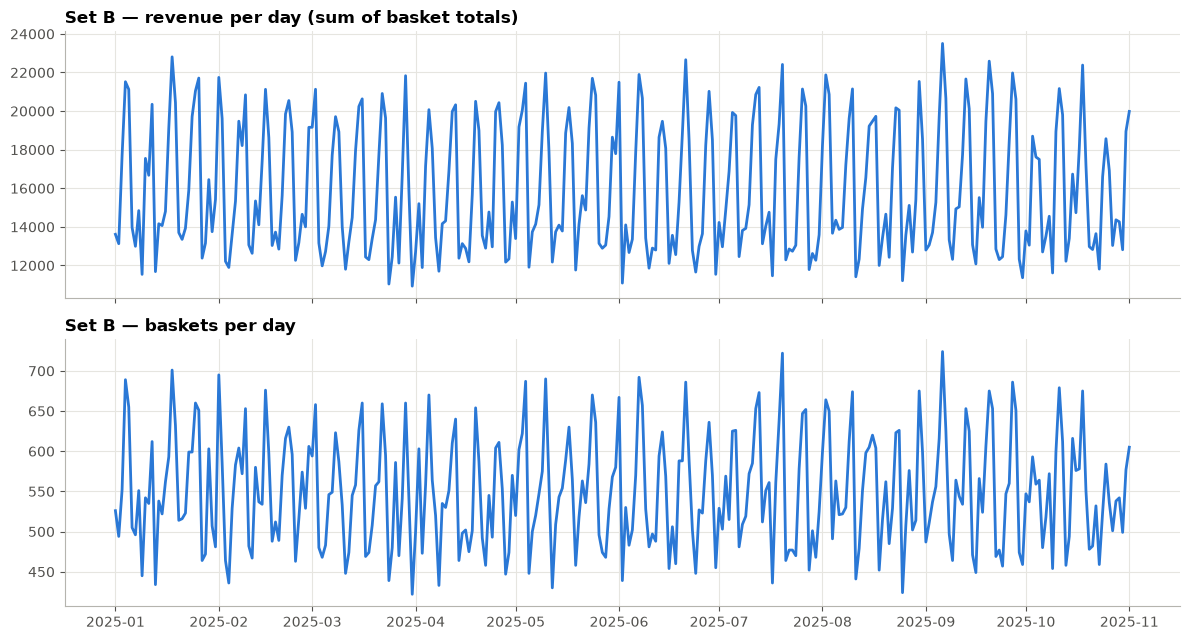

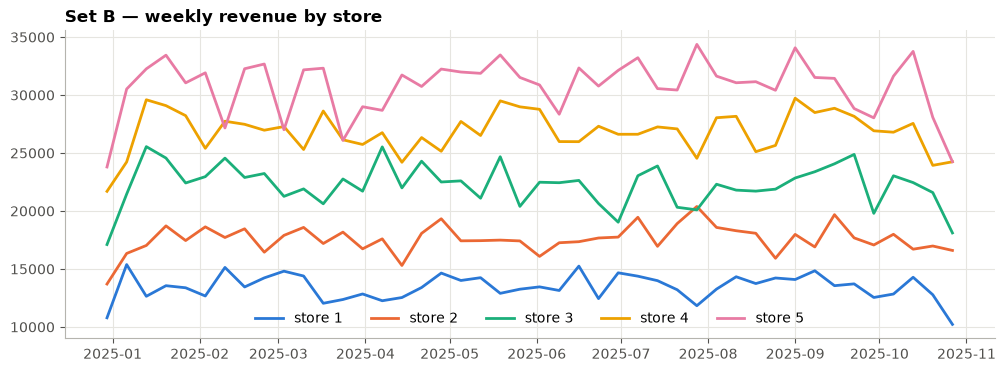

In [22]:
daily = b_baskets.set_index('timestamp').resample('D').agg({'total': 'sum', 'transaction_id': 'count'})
fig, axes = plt.subplots(2, 1, figsize=(12, 6.5), sharex=True)
axes[0].plot(daily.index, daily['total'], color=BLUE)
axes[0].set_title('Set B — revenue per day (sum of basket totals)')
axes[1].plot(daily.index, daily['transaction_id'], color=BLUE)
axes[1].set_title('Set B — baskets per day')
plt.tight_layout(); plt.show()

per_store = b_baskets.groupby([b_baskets.timestamp.dt.to_period('W').dt.start_time, 'store_id'])['total'].sum().unstack()
fig, ax = plt.subplots(figsize=(12, 4))
for i, s in enumerate(per_store.columns):
    ax.plot(per_store.index, per_store[s], color=CAT[i], label=f'store {s}')
ax.set_title('Set B — weekly revenue by store'); ax.legend(frameon=False, ncol=5)
plt.show()

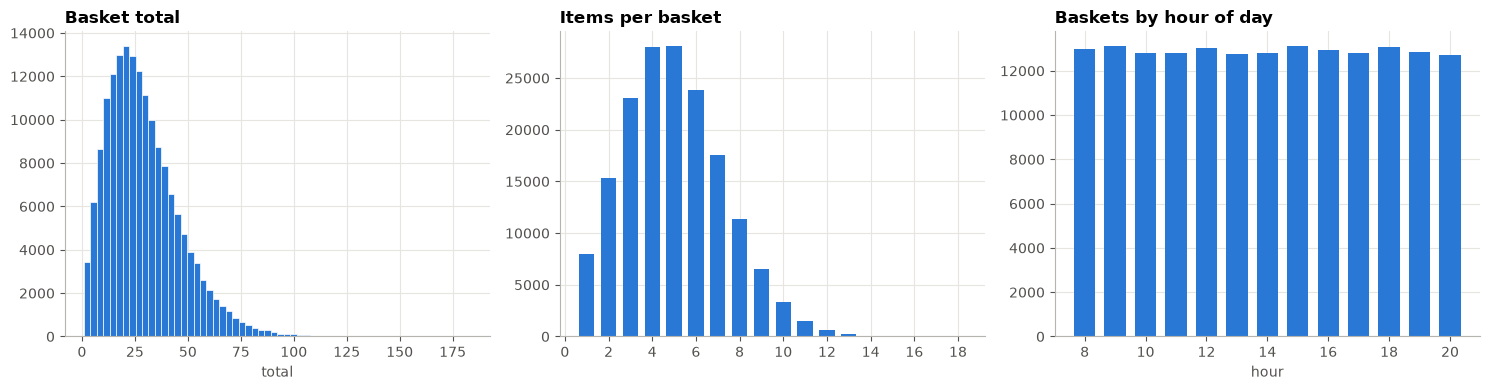

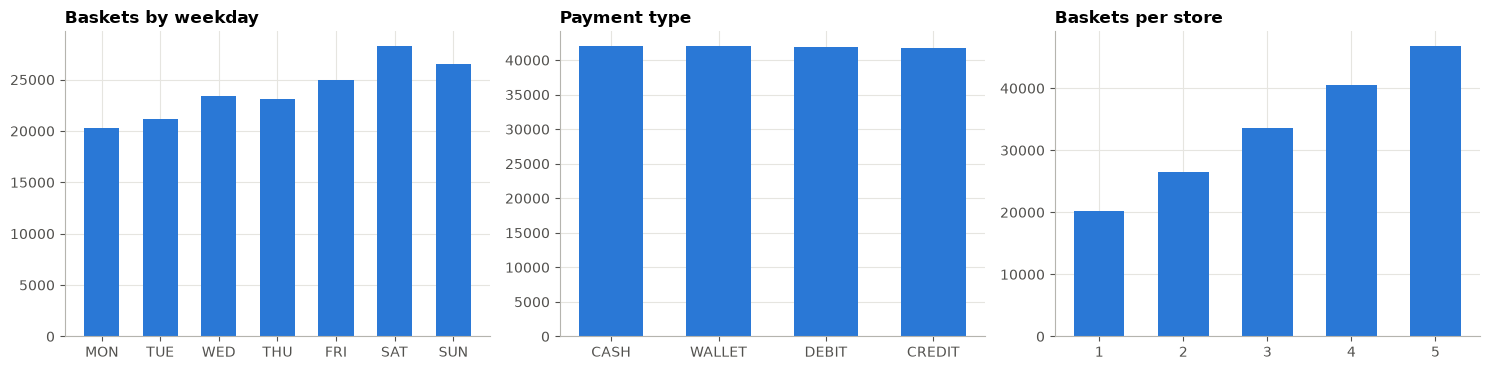

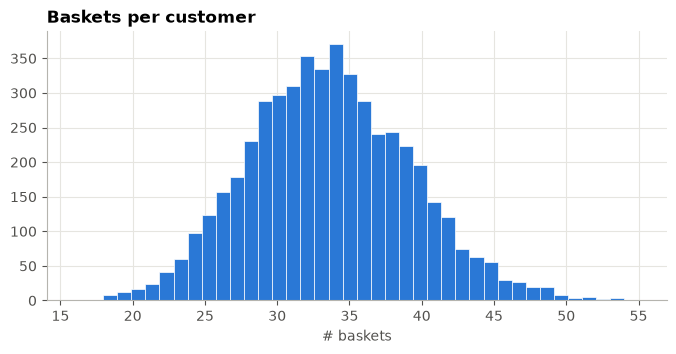

In [23]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
axes[0].hist(b_baskets['total'], bins=60, color=BLUE, edgecolor='white', linewidth=0.5)
axes[0].set_title('Basket total'); axes[0].set_xlabel('total')
it = b_baskets['items'].value_counts().sort_index()
axes[1].bar(it.index, it.values, color=BLUE, width=0.7)
axes[1].set_title('Items per basket'); axes[1].xaxis.set_major_locator(mtick.MaxNLocator(integer=True))
hr = b_baskets.timestamp.dt.hour.value_counts().sort_index()
axes[2].bar(hr.index, hr.values, color=BLUE, width=0.7)
axes[2].set_title('Baskets by hour of day'); axes[2].set_xlabel('hour')
plt.tight_layout(); plt.show()

fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))
order = ['MONDAY', 'TUESDAY', 'WEDNESDAY', 'THURSDAY', 'FRIDAY', 'SATURDAY', 'SUNDAY']
wd = b_baskets['weekday'].value_counts().reindex(order)
axes[0].bar([d[:3] for d in wd.index], wd.values, color=BLUE, width=0.6); axes[0].set_title('Baskets by weekday')
pt = b_baskets['payment_type'].value_counts()
axes[1].bar(pt.index, pt.values, color=BLUE, width=0.6); axes[1].set_title('Payment type')
st = b_baskets['store_id'].value_counts().sort_index()
axes[2].bar(st.index.astype(str), st.values, color=BLUE, width=0.6); axes[2].set_title('Baskets per store')
plt.tight_layout(); plt.show()

cust = b_baskets['customer_id'].value_counts()
fig, ax = plt.subplots(figsize=(8, 3.5))
ax.hist(cust, bins=40, color=BLUE, edgecolor='white', linewidth=0.5)
ax.set_title('Baskets per customer'); ax.set_xlabel('# baskets')
plt.show()

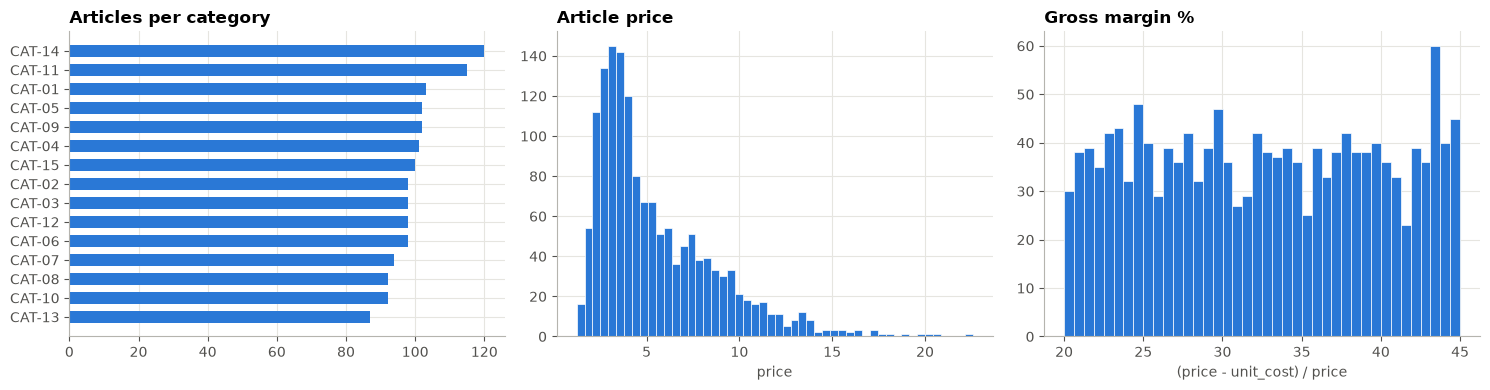

In [24]:
# Articles: category mix, price & margin
b_articles['margin_%'] = 100 * (b_articles.price - b_articles.unit_cost) / b_articles.price
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
cat = b_articles['category'].value_counts().sort_values()
axes[0].barh(cat.index, cat.values, color=BLUE, height=0.6); axes[0].set_title('Articles per category')
axes[1].hist(b_articles['price'], bins=50, color=BLUE, edgecolor='white', linewidth=0.5)
axes[1].set_title('Article price'); axes[1].set_xlabel('price')
axes[2].hist(b_articles['margin_%'], bins=40, color=BLUE, edgecolor='white', linewidth=0.5)
axes[2].set_title('Gross margin %'); axes[2].set_xlabel('(price - unit_cost) / price')
plt.tight_layout(); plt.show()

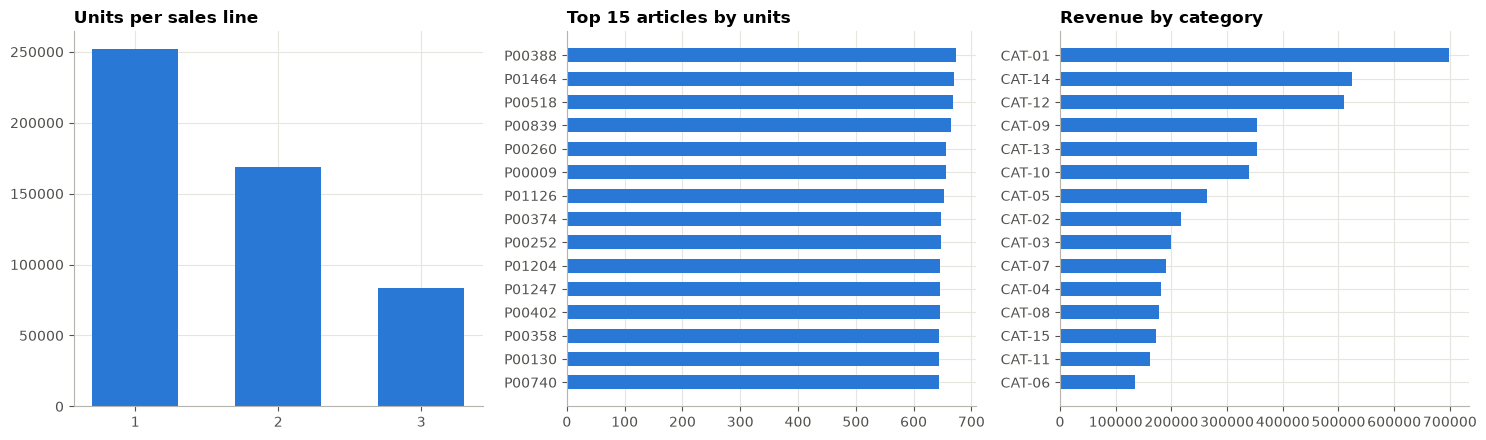

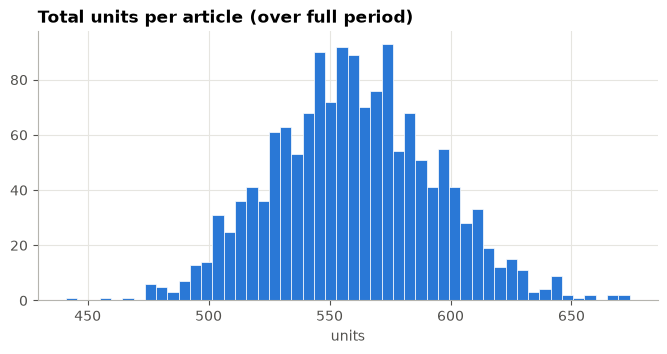

In [25]:
# Sales lines: units per line, top articles & category revenue
sl = b_sales_lines.merge(b_articles[['article_id', 'category']], on='article_id', how='left')
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
un = sl['units'].value_counts().sort_index()
axes[0].bar(un.index.astype(str), un.values, color=BLUE, width=0.6); axes[0].set_title('Units per sales line')
top = sl.groupby('article_id')['units'].sum().nlargest(15).sort_values()
axes[1].barh(top.index, top.values, color=BLUE, height=0.6); axes[1].set_title('Top 15 articles by units')
crev = sl.groupby('category')['line_total'].sum().sort_values()
axes[2].barh(crev.index, crev.values, color=BLUE, height=0.6); axes[2].set_title('Revenue by category')
plt.tight_layout(); plt.show()

art_units = sl.groupby('article_id')['units'].sum()
fig, ax = plt.subplots(figsize=(8, 3.5))
ax.hist(art_units, bins=50, color=BLUE, edgecolor='white', linewidth=0.5)
ax.set_title('Total units per article (over full period)'); ax.set_xlabel('units')
plt.show()

Promotion period: 2024-12-29 → 2025-11-01


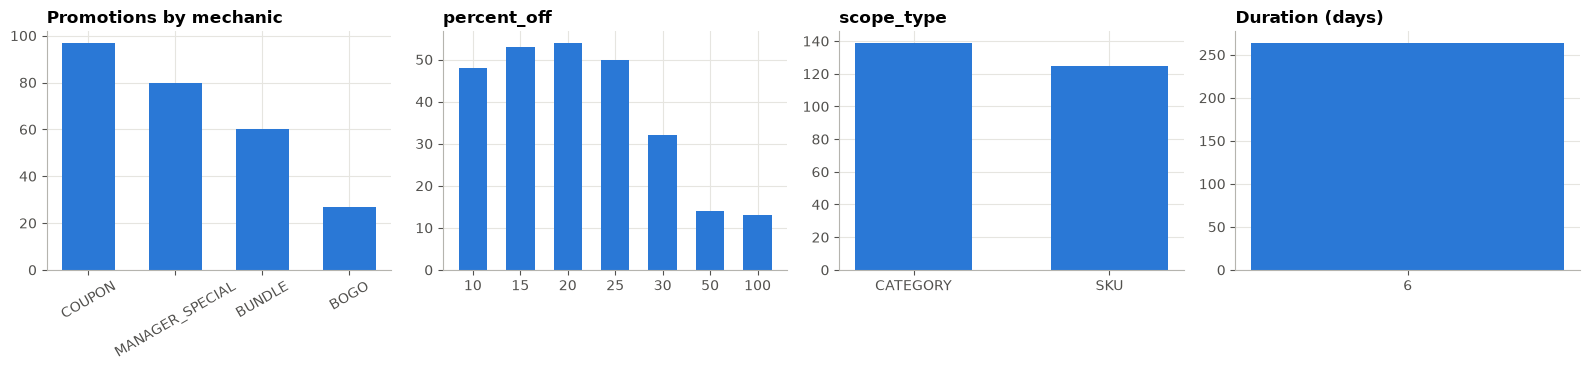

,count,sum,mean
mechanic,,,
BOGO,6612,9807.84,1.483339
BUNDLE,15018,9626.10,0.640971
COUPON,28693,50584.83,1.762968
MANAGER_SPECIAL,18250,26720.30,1.464126


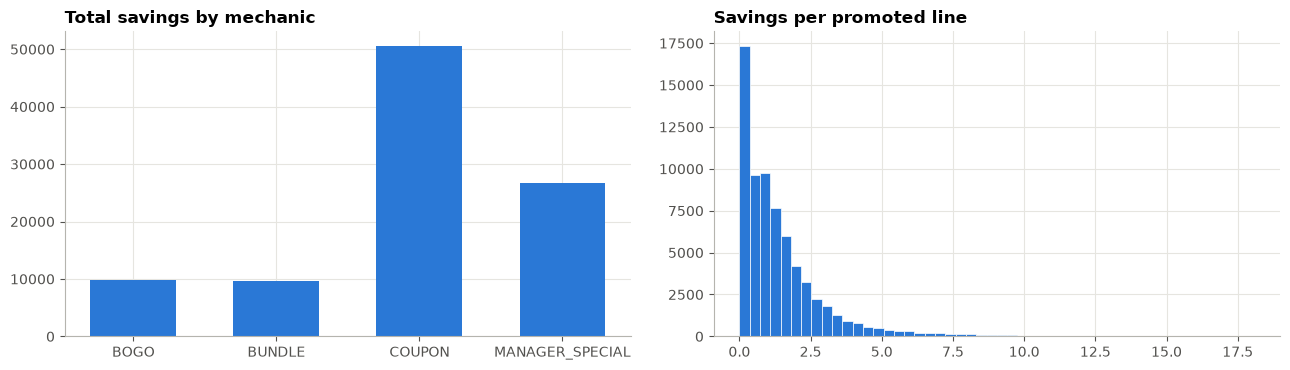

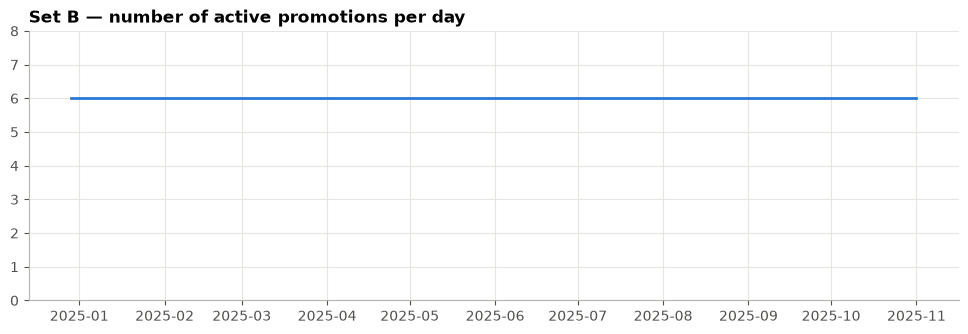

In [26]:
# Promotions
print('Promotion period:', b_promotions.start_date.min().date(), '→', b_promotions.end_date.max().date())
b_promotions['duration_days'] = (b_promotions.end_date - b_promotions.start_date).dt.days
fig, axes = plt.subplots(1, 4, figsize=(16, 3.8))
m = b_promotions['mechanic'].value_counts()
axes[0].bar(m.index, m.values, color=BLUE, width=0.6); axes[0].set_title('Promotions by mechanic')
axes[0].tick_params(axis='x', rotation=30)
p = b_promotions['percent_off'].value_counts().sort_index()
axes[1].bar(p.index.astype(str), p.values, color=BLUE, width=0.6); axes[1].set_title('percent_off')
s = b_promotions['scope_type'].value_counts()
axes[2].bar(s.index, s.values, color=BLUE, width=0.6); axes[2].set_title('scope_type')
d = b_promotions['duration_days'].value_counts().sort_index()
axes[3].bar(d.index.astype(str), d.values, color=BLUE, width=0.6); axes[3].set_title('Duration (days)')
plt.tight_layout(); plt.show()

fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))
sv = b_basket_promotions.groupby('mechanic')['savings'].agg(['count', 'sum', 'mean'])
display(sv)
axes[0].bar(sv.index, sv['sum'], color=BLUE, width=0.6); axes[0].set_title('Total savings by mechanic')
axes[1].hist(b_basket_promotions['savings'], bins=50, color=BLUE, edgecolor='white', linewidth=0.5)
axes[1].set_title('Savings per promoted line')
plt.tight_layout(); plt.show()

active = pd.Series(0, index=pd.date_range(b_promotions.start_date.min(), b_promotions.end_date.max()))
for s_, e_ in zip(b_promotions.start_date, b_promotions.end_date):
    active[s_:e_] += 1
fig, ax = plt.subplots(figsize=(12, 3.5))
ax.plot(active.index, active.values, color=BLUE, drawstyle='steps-post')
ax.set_ylim(0, active.max() + 2); ax.set_title('Set B — number of active promotions per day')
plt.show()

Stock rows below reorder point: 11.0%
Rows with price override: 35.1%


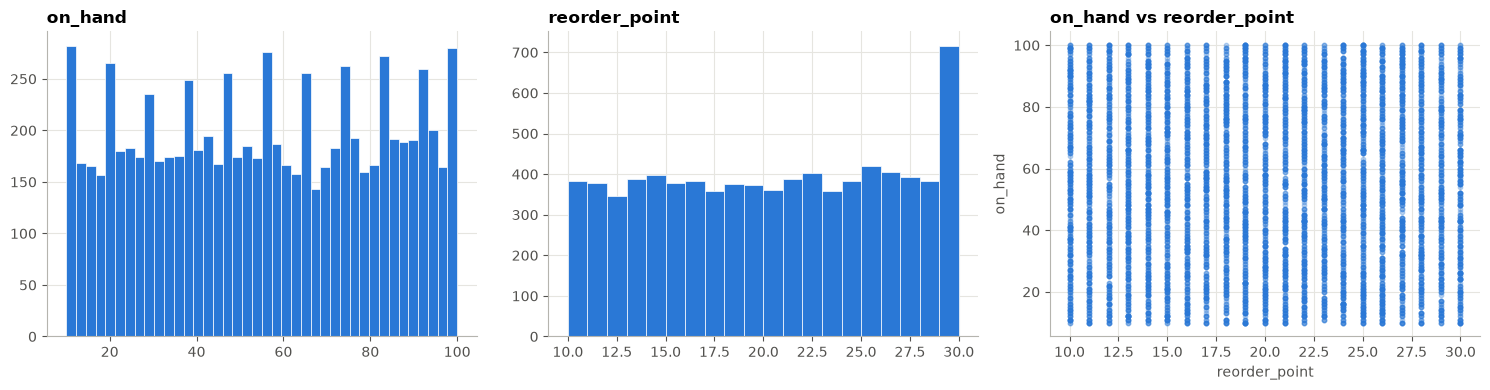

,count,mean,std,min,25%,50%,75%,max
reason,,,,,,,,
REPLENISH,24639.0,65.758675,19.13222,30.0,52.0,64.0,82.0,100.0
STOCKOUT,1576.0,0.000000,0.00000,0.0,0.0,0.0,0.0,0.0


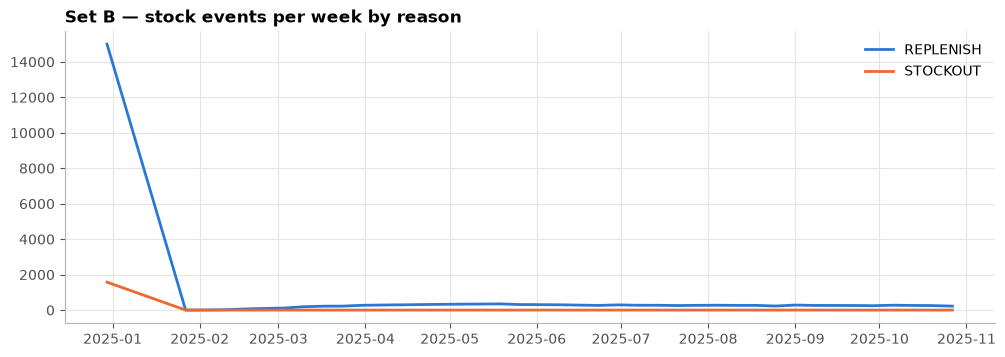

In [27]:
# Stock levels & stock events
b_stock['below_reorder'] = b_stock.on_hand < b_stock.reorder_point
print(f"Stock rows below reorder point: {100*b_stock.below_reorder.mean():.1f}%")
print(f"Rows with price override: {100*b_stock.price_override_cents.notna().mean():.1f}%")
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
axes[0].hist(b_stock['on_hand'], bins=40, color=BLUE, edgecolor='white', linewidth=0.5); axes[0].set_title('on_hand')
axes[1].hist(b_stock['reorder_point'], bins=20, color=BLUE, edgecolor='white', linewidth=0.5); axes[1].set_title('reorder_point')
axes[2].scatter(b_stock['reorder_point'], b_stock['on_hand'], s=10, alpha=0.3, color=BLUE)
axes[2].set_xlabel('reorder_point'); axes[2].set_ylabel('on_hand'); axes[2].set_title('on_hand vs reorder_point')
plt.tight_layout(); plt.show()

display(b_stock_events.groupby('reason')['delta'].describe())
ev = b_stock_events.groupby([b_stock_events.timestamp.dt.to_period('W').dt.start_time, 'reason']).size().unstack(fill_value=0)
fig, ax = plt.subplots(figsize=(12, 3.8))
for i, r in enumerate(ev.columns):
    ax.plot(ev.index, ev[r], color=CAT[i], label=r)
ax.set_title('Set B — stock events per week by reason'); ax.legend(frameon=False)
plt.show()

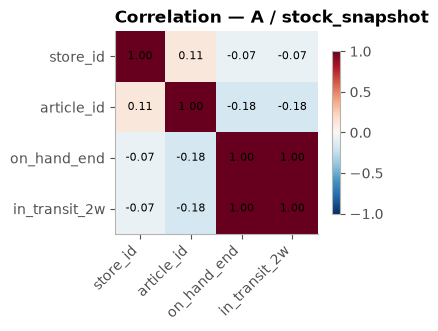

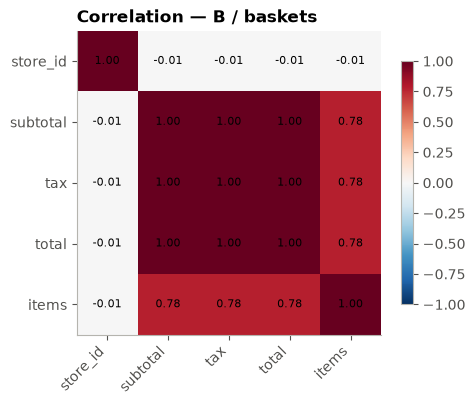

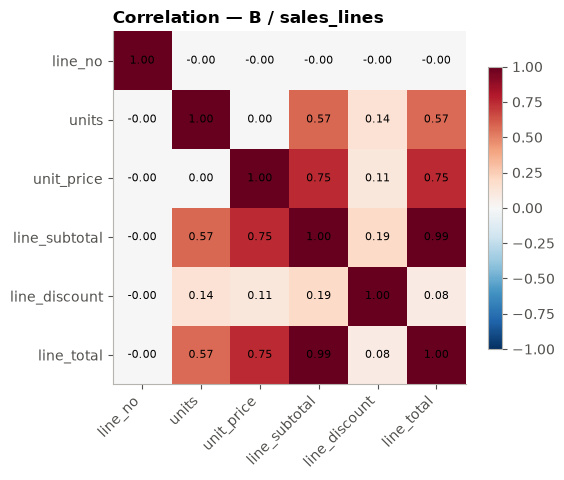

In [28]:
# Correlations between numeric columns of the main fact tables
for name, df in [('A / stock_snapshot', a_stock_snapshot), ('B / baskets', b_baskets), ('B / sales_lines', b_sales_lines)]:
    num = df.select_dtypes('number').loc[:, lambda d: d.nunique() > 1]
    corr = num.corr()
    fig, ax = plt.subplots(figsize=(1 + 0.8 * len(corr), 0.6 + 0.7 * len(corr)))
    im = ax.imshow(corr, cmap='RdBu_r', vmin=-1, vmax=1)
    ax.set_xticks(range(len(corr)), corr.columns, rotation=45, ha='right')
    ax.set_yticks(range(len(corr)), corr.columns); ax.grid(False)
    for i in range(len(corr)):
        for j in range(len(corr)):
            ax.text(j, i, f'{corr.iat[i, j]:.2f}', ha='center', va='center', fontsize=8)
    fig.colorbar(im, ax=ax, shrink=0.8); ax.set_title(f'Correlation — {name}')
    plt.tight_layout(); plt.show()

Random Analysis

In [29]:
# 1a. Every combination of store_format and format, with how many pairs and stores have it
combo = (a_articles
         .groupby(['store_format', 'format'])
         .agg(pairs=('article_id', 'size'), stores=('store_id', 'nunique'))
         .reset_index())
print(combo)
# 3 rows = they always appear together (same thing coded twice)
# more than 3 rows = they are independent attributes

# 1b. Cross-table at store level (one row per store, so big stores don't dominate)
stores = a_articles[['store_id', 'store_format', 'format']].drop_duplicates()
print(pd.crosstab(stores.store_format, stores.format))

# 1c. Does any store have more than one format value? (should be 0)
print('stores with >1 combination:',
      (stores.groupby('store_id').size() > 1).sum())

# 1d. Store size per format: rough idea of small/medium/large
size = (a_articles.groupby('store_id').article_id.nunique().rename('n_articles')
        .to_frame().join(stores.set_index('store_id')))
print(size.groupby(['store_format', 'format']).n_articles.describe())
print('store 61:', size.loc[61].to_dict())

   store_format  format  pairs  stores
0             1      13     83      60
1             2     216    513       5
2             5     521      3       2
format        13   216  521
store_format               
1              60    0    0
2               0    5    0
5               0    0    2
stores with >1 combination: 0
                     count        mean        std   min    25%    50%     75%    max
store_format format                                                                 
1            13       60.0    1.383333   0.523731   1.0   1.00    1.0    2.00    3.0
2            216       5.0  102.600000  80.204738  12.0  54.00  100.0  123.00  224.0
5            521       2.0    1.500000   0.707107   1.0   1.25    1.5    1.75    2.0
store 61: {'n_articles': 224, 'store_format': 2, 'format': 216}


In [30]:
# 2a. The top rows by units, with product hierarchy and store format added
w = a_weekly.merge(a_articles, on=['store_id', 'article_id'], how='left')
top = w.nlargest(10, 'units')
print(top[['store_id', 'article_id', 'week_start', 'units', 'in_stock',
           'product_group', 'department', 'store_format']])

# 2b. The 494 row in the context of its own series
r = top.iloc[0]
s = w[(w.store_id == r.store_id) & (w.article_id == r.article_id)].set_index('week_start').units
print(f"\nstore {r.store_id}, article {r.article_id}, week {r.week_start.date()}")
print('this pair normally:', s.describe()[['mean', '50%', '75%', 'max']].round(2).to_dict())
print('weeks around it:\n', s.loc[r.week_start - pd.Timedelta(weeks=3):
                                  r.week_start + pd.Timedelta(weeks=3)])

# 2c. Same week, same product group, other stores: was the whole group busy that week?
pg = w[(w.product_group == r.product_group) & (w.week_start == r.week_start)]
print('\nsame product group, same week, other stores:')
print(pg.groupby('store_id').units.sum().sort_values(ascending=False).head(10))

# 2d. Same week, whole department: a department-wide event?
dep_week = w[w.department == r.department].groupby('week_start').units.mean()
print('\ndepartment mean that week vs normal:',
      round(dep_week.loc[r.week_start], 2), 'vs', round(dep_week.mean(), 2))

# 2e. How unusual is it? Robust z-score within its own series
#     (median absolute deviation; plain std breaks on sparse 0/1/2 data)
med = s.median()
mad = (s - med).abs().median() or 1  # avoid dividing by 0 when MAD = 0
print('robust z-score:', round((r.units - med) / (1.4826 * mad), 1))

# 2f. How many other extreme rows are there? (same method, all pairs)
def robust_z(x):
    m = x.median()
    d = (x - m).abs().median() or 1
    return (x - m) / (1.4826 * d)
w['rz'] = w.groupby(['store_id', 'article_id']).units.transform(robust_z)
print('\nrows with robust z > 20:', (w.rz > 20).sum())
print(w[w.rz > 20].groupby('department').size().sort_values(ascending=False).head())

       store_id  article_id week_start  units  in_stock  product_group  department  store_format
45735        61         124 2021-11-08  494.0      True         240201          24             2
45840        61         124 2023-11-13  492.0      True         240201          24             2
45788        61         124 2022-11-14  443.0      True         240201          24             2
33201        61          23 2021-12-20  407.0      True         140402          14             2
33303        61          23 2023-12-04  400.0      True         140402          14             2
87818        63          23 2022-01-03  363.0      True         140402          14             2
91545        63         124 2023-11-13  342.0      True         240201          24             2
33305        61          23 2023-12-18  333.0      True         140402          14             2
15650        60          23 2023-12-18  307.0      True         140402          14             2
21975        60         125 20

# 8. Test shop — what has to be forecast

**The task (from the README + lemebase.com/hackathon/submit):**
- One real shop, *not* one of the four sets. `history.parquet` = weekly history per article; the **13 weeks after it are hidden**.
- Forecast **w1 … w13 = the 13 Mondays 2023-04-24 → 2023-07-17**, for **all 2,904 articles** → 2,904 × 13 = 37,752 numbers.
- Upload: CSV with header `article_id, w1, …, w13`, one row per article (decimals allowed).
- **Score = (1 − MASE) × 100**, higher is better. Per week: |error| ÷ the article's typical week-to-week move in its history; averaged per article, then over all articles (every article weighs the same).
- Reference points: naive (last value) ≈ −64.5, AutoARIMA ≈ −33.7, 0 = you miss by one typical weekly move, 100 = perfect.
- The live leaderboard scores only w1–w7; the **final score uses the hidden w8–w13** → don't tune to the leaderboard.

In [ ]:
ts = pd.read_parquet(BASE / 'test-shop' / 'history.parquet')
ts['week_start'] = pd.to_datetime(ts['week_start'])
ts = ts.sort_values(['article_id', 'week_start']).reset_index(drop=True)

print(f'{len(ts):,} rows x {ts.shape[1]} cols')
display(profile(ts))
display(ts.describe(include='all').T)

## 8.1 Layout: a full article × week grid

In [ ]:
weeks = np.sort(ts.week_start.unique())
n_art, n_wk = ts.article_id.nunique(), len(weeks)
print(f'Articles: {n_art:,} | Weeks: {n_wk} ({pd.Timestamp(weeks[0]).date()} → {pd.Timestamp(weeks[-1]).date()})')
print('Rows = articles × weeks?', len(ts) == n_art * n_wk)
print('Every week_start is a Monday?', (ts.week_start.dt.day_of_week == 0).all())
print('Gaps between weeks (days):', np.unique(np.diff(weeks).astype('timedelta64[D]').astype(int)))
print('Duplicate (article, week) rows:', ts.duplicated(['article_id', 'week_start']).sum())
print('Non-integer units:', (ts.units % 1 != 0).sum(), '| negative units:', (ts.units < 0).sum())

# The horizon to forecast
horizon = pd.date_range(pd.Timestamp(weeks[-1]) + pd.Timedelta(weeks=1), periods=13, freq='W-MON')
display(pd.DataFrame({'col': [f'w{i}' for i in range(1, 14)], 'week_start': horizon.date,
                      'scored': ['live (w1-w7)'] * 7 + ['final, hidden (w8-w13)'] * 6}))

# Wide matrix: one row per article, one column per week (the natural shape for this task)
Y = ts.pivot(index='article_id', columns='week_start', values='units').sort_index(axis=1)
OH = ts.pivot(index='article_id', columns='week_start', values='on_hand').sort_index(axis=1)
print('Wide matrix:', Y.shape)

In [ ]:
wk_tot = Y.sum()
fig, ax = plt.subplots(figsize=(13, 4))
ax.plot(wk_tot.index, wk_tot.values, color=BLUE)
ax.axvspan(horizon[0], horizon[7], color=AQUA, alpha=0.15, label='w1–w7 (live score)')
ax.axvspan(horizon[7], horizon[-1] + pd.Timedelta(days=6), color=ORANGE, alpha=0.15, label='w8–w13 (final score)')
ax.axvline(horizon[0], color='#52514e', linewidth=1, linestyle='--')
ax.set_title('Test shop — total units per week, with the forecast horizon'); ax.set_ylabel('units')
ax.legend(frameon=False, loc='upper right')
plt.show()

# Same window in earlier years: does the forecast season look different?
fig, ax = plt.subplots(figsize=(13, 4))
for i, y in enumerate(sorted(wk_tot.index.year.unique())):
    s = wk_tot[wk_tot.index.year == y]
    ax.plot(s.index.isocalendar().week.values, s.values, color=CAT[i], label=str(y), marker='o', markersize=3, linewidth=1.5)
ax.axvspan(horizon[0].isocalendar().week, horizon[-1].isocalendar().week, color='#b5b4ae', alpha=0.2, label='horizon weeks')
ax.set_xlabel('ISO week (of the shifted dates)'); ax.set_title('Test shop — total units by week of year, per year')
ax.legend(frameon=False, ncol=5)
plt.show()

print('Total units in the horizon weeks of earlier years vs the 13 weeks before them:')
for y in [2021, 2022]:
    h = wk_tot[(wk_tot.index >= horizon[0] - pd.DateOffset(years=2023 - y)) & (wk_tot.index <= horizon[-1] - pd.DateOffset(years=2023 - y))]
    pre = wk_tot[(wk_tot.index < h.index.min()) & (wk_tot.index >= h.index.min() - pd.Timedelta(weeks=13))]
    print(f'  {y}: horizon mean {h.mean():,.0f} / previous 13w mean {pre.mean():,.0f} = {h.mean() / pre.mean():.2f}')

**Note:** dates were shifted by a fixed number of whole weeks, so calendar events (Easter, Christmas, holidays) are **not** on their real dates. Seasonality has to be learned from the data itself (e.g. 52-week lags), not from a holiday calendar.

## 8.2 Demand profile: sparse, skewed, concentrated

In [ ]:
art_tot = Y.sum(axis=1).sort_values(ascending=False)
print(f'Zero-unit rows: {100 * (ts.units == 0).mean():.1f}%')
print(f'Units per article over the full history: median {art_tot.median():.0f}, mean {art_tot.mean():.0f}, max {art_tot.max():,.0f}')
print(f'Top 1% of articles = {100 * art_tot.head(int(n_art * .01)).sum() / art_tot.sum():.0f}% of units, '
      f'top 10% = {100 * art_tot.head(int(n_art * .10)).sum() / art_tot.sum():.0f}%')

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
axes[0].hist(np.log10(art_tot), bins=50, color=BLUE, edgecolor='white', linewidth=0.5)
axes[0].set_title('Total units per article'); axes[0].set_xlabel('log10(units)')
cum = art_tot.cumsum() / art_tot.sum()
axes[1].plot(np.arange(1, n_art + 1) / n_art * 100, cum.values * 100, color=BLUE)
axes[1].set_title('Concentration: cumulative % of units'); axes[1].set_xlabel('% of articles (largest first)')
axes[1].yaxis.set_major_formatter(mtick.PercentFormatter()); axes[1].xaxis.set_major_formatter(mtick.PercentFormatter())
zero_pct = (Y == 0).mean(axis=1) * 100
axes[2].hist(zero_pct, bins=40, color=BLUE, edgecolor='white', linewidth=0.5)
axes[2].set_title('% of weeks with 0 units, per article'); axes[2].set_xlabel('% zero weeks')
plt.tight_layout(); plt.show()

In [ ]:
# Syntetos–Boylan classification: ADI = avg interval between sales, CV² = variability of non-zero sizes
def sb_class(row):
    nz = row[row > 0]
    adi = len(row) / len(nz)
    cv2 = (nz.std() / nz.mean()) ** 2 if len(nz) > 1 else 0.0
    return pd.Series({'adi': adi, 'cv2': cv2})

sb = Y.apply(sb_class, axis=1)
sb['class'] = np.select([(sb.adi < 1.32) & (sb.cv2 < 0.49), (sb.adi >= 1.32) & (sb.cv2 < 0.49), sb.adi < 1.32],
                        ['smooth', 'intermittent', 'erratic'], 'lumpy')
display(sb['class'].value_counts().to_frame('articles').assign(pct=lambda d: (100 * d.articles / n_art).round(1)))

fig, ax = plt.subplots(figsize=(8, 5))
for i, c in enumerate(['smooth', 'intermittent', 'erratic', 'lumpy']):
    s = sb[sb['class'] == c]
    ax.scatter(s.adi, s.cv2, s=8, alpha=0.5, color=CAT[i], label=f'{c} ({len(s)})')
ax.axvline(1.32, color='#52514e', linewidth=1, linestyle='--'); ax.axhline(0.49, color='#52514e', linewidth=1, linestyle='--')
ax.set_xscale('log'); ax.set_xlabel('ADI (weeks between sales, log)'); ax.set_ylabel('CV² of non-zero demand')
ax.set_title('Demand patterns (Syntetos–Boylan)'); ax.legend(frameon=False)
plt.show()

## 8.3 Article lifecycle: new, active, and dead articles

In [ ]:
last_wk = pd.Timestamp(weeks[-1])
sold = Y > 0
first_sale = sold.idxmax(axis=1)
last_sale = sold.iloc[:, ::-1].idxmax(axis=1)
wks_since = ((last_wk - last_sale).dt.days // 7)

buckets = pd.cut(wks_since, [-1, 0, 4, 8, 13, 26, 52, 200],
                 labels=['sold last week', '1–4', '5–8', '9–13', '14–26', '27–52', '>52 weeks'])
bc = buckets.value_counts().sort_index()
display(bc.to_frame('articles'))
print(f'Articles with no sale in the last 8 weeks (baselines forecast 0 for these): {(wks_since >= 8).sum():,}')
print(f'Articles whose first sale is in the last 26 weeks (new, short history): {(first_sale > last_wk - pd.Timedelta(weeks=26)).sum():,}')

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
axes[0].bar(bc.index.astype(str), bc.values, color=BLUE, width=0.6)
axes[0].set_title('Weeks since last sale (at the end of history)')
active = pd.Series([((first_sale <= w) & (last_sale >= w)).sum() for w in Y.columns], index=Y.columns)
axes[1].plot(active.index, active.values, color=BLUE)
axes[1].set_title('Articles "alive" per week (between first and last sale)')
plt.tight_layout(); plt.show()

## 8.4 `on_hand`: a noisy stock signal

In [ ]:
print(f'on_hand missing: {100 * ts.on_hand.isna().mean():.1f}% (before an article\'s first ledger entry)')
print(f'on_hand negative: {(ts.on_hand < 0).sum()} rows | on_hand == 0: {100 * (ts.on_hand == 0).mean():.1f}%')
print('on_hand quantiles:', ts.on_hand.quantile([.5, .9, .99, .999, 1]).round(0).to_dict())

prev_oh = OH.shift(1, axis=1)
print(f'Weeks with 0 units AND stock <= 0 at the start (possible stock-out, demand hidden): {100 * ((Y == 0) & (prev_oh <= 0)).values.mean():.1f}%')
print(f'Weeks with units > 0 although stock <= 0 at the start (ledger inconsistency): {100 * ((Y > 0) & (prev_oh <= 0)).values.mean():.1f}%')

# A few example articles from different volume tiers: units and stock on separate panels
examples = [art_tot.index[5], art_tot.index[300], art_tot.index[1200], art_tot.index[2500]]
fig, axes = plt.subplots(4, 2, figsize=(15, 10), sharex=True)
for r, a in enumerate(examples):
    axes[r, 0].bar(Y.columns, Y.loc[a], width=5, color=BLUE); axes[r, 0].set_title(f'{a} — units / week ({sb.loc[a, "class"]})')
    axes[r, 1].plot(OH.columns, OH.loc[a], color=VIOLET, drawstyle='steps-post'); axes[r, 1].set_title(f'{a} — on_hand (end of week)')
plt.tight_layout(); plt.show()

## 8.5 Understanding the metric (MASE) and what it rewards
For each article: `MASE = mean_h |y_h − ŷ_h| / mean_t |y_t − y_{t-1}|` (denominator taken over the history). The score averages MASE over articles **unweighted**, so a slow seller weighs exactly as much as a best seller.

In [ ]:
den_full = Y.diff(axis=1).abs().mean(axis=1)
print('Denominator (avg. absolute week-to-week change) over full history:')
print(den_full.describe(percentiles=[.1, .25, .5, .75, .9]).round(3).to_string())

fig, ax = plt.subplots(figsize=(10, 3.8))
ax.hist(np.log10(den_full[den_full > 0]), bins=60, color=BLUE, edgecolor='white', linewidth=0.5)
ax.set_xlabel('log10(denominator)'); ax.set_title('MASE denominator per article — tiny values make errors explode')
plt.show()
print(f'{(den_full < 0.1).sum()} articles have a denominator < 0.1: forecasting 1 unit/week for them when the truth is 0 gives MASE > 10.')

## 8.6 Fair offline validation: simulate the hidden 13 weeks
Hold out the **last 13 weeks of the history** (same horizon length), fit only on the weeks before, and score with the same MASE. Report w1–w7 and w8–w13 separately, like the leaderboard. Nothing in the holdout is used for fitting.

In [ ]:
H = 13
def split(Y, cutoff_offset=0):
    end = Y.shape[1] - cutoff_offset
    return Y.iloc[:, :end - H], Y.iloc[:, end - H:end]

def mase_score(train, test, F):
    F = np.asarray(F, dtype=float)
    den = train.diff(axis=1).abs().mean(axis=1).values
    err = np.abs(test.values - F)
    np.seterr(divide='ignore', invalid='ignore')  # articles with a 0 denominator are dropped below
    out = {}
    for name, cols in [('all w1-w13', slice(0, H)), ('w1-w7 (live)', slice(0, 7)), ('w8-w13 (final)', slice(7, H))]:
        m = err[:, cols].mean(axis=1) / den
        m = m[np.isfinite(m)]               # articles with no movement in train can't be scored
        out[name] = round((1 - m.mean()) * 100, 1)
    return out

tr, te = split(Y)
print('Train:', tr.columns[0].date(), '→', tr.columns[-1].date(), '| Holdout:', te.columns[0].date(), '→', te.columns[-1].date())
print('Articles not scorable in this backtest (no movement before the holdout):', (tr.diff(axis=1).abs().mean(axis=1) == 0).sum())

In [ ]:
rep = lambda v: np.repeat(np.asarray(v, dtype=float)[:, None], H, axis=1)
def dead_to_zero(tr, F, k=8):
    return np.where((tr.iloc[:, -k:].sum(axis=1) == 0).values[:, None], 0, F)

baselines = {
    'zero':                     lambda tr: np.zeros((len(tr), H)),
    'naive (last week)':        lambda tr: rep(tr.iloc[:, -1]),
    'seasonal naive (52w ago)': lambda tr: tr.iloc[:, -52:-52 + H].values,
    'mean last 13w':            lambda tr: rep(tr.iloc[:, -13:].mean(axis=1)),
    'mean last 52w':            lambda tr: rep(tr.iloc[:, -52:].mean(axis=1)),
    'median last 8w':           lambda tr: rep(tr.iloc[:, -8:].median(axis=1)),
    'median last 13w':          lambda tr: rep(tr.iloc[:, -13:].median(axis=1)),
    'median last 26w':          lambda tr: rep(tr.iloc[:, -26:].median(axis=1)),
    'median last 52w':          lambda tr: rep(tr.iloc[:, -52:].median(axis=1)),
    'mean 13w + dead(8w)→0':    lambda tr: dead_to_zero(tr, rep(tr.iloc[:, -13:].mean(axis=1))),
}

# Score on the last 13 weeks and on an earlier 13-week window to check stability
rows = []
for name, f in baselines.items():
    for off, label in [(0, 'holdout = last 13w'), (13, 'holdout = 13w before that')]:
        tr_, te_ = split(Y, off)
        rows.append({'model': name, 'window': label, **mase_score(tr_, te_, f(tr_))})
bt = pd.DataFrame(rows)
bt_wide = bt.pivot(index='model', columns='window', values='all w1-w13').sort_values('holdout = last 13w')
display(bt[bt.window == 'holdout = last 13w'].drop(columns='window').set_index('model').sort_values('all w1-w13', ascending=False))
display(bt_wide.sort_values('holdout = last 13w', ascending=False))

fig, ax = plt.subplots(figsize=(10, 4.5))
ax.barh(bt_wide.index, bt_wide['holdout = last 13w'], color=BLUE, height=0.6)
ax.axvline(-33.7, color=RED, linewidth=1.5, linestyle='--'); ax.text(-33.7, len(bt_wide) - 0.4, ' AutoARIMA (site)', color='#52514e', fontsize=9)
ax.axvline(-64.5, color='#52514e', linewidth=1, linestyle=':'); ax.text(-64.5, len(bt_wide) - 0.4, ' naive (site)', color='#52514e', fontsize=9)
ax.axvline(0, color='#52514e', linewidth=0.8)
ax.set_title('Backtest score (1 − MASE) × 100 on the last 13 weeks — higher is better')
plt.tight_layout(); plt.show()

In [ ]:
# Where does the error come from? Score of the best simple baseline, per demand class and volume tier
tr, te = split(Y)
F = baselines['median last 13w'](tr)
den = tr.diff(axis=1).abs().mean(axis=1)
per_art = pd.DataFrame({'mase': np.abs(te.values - F).mean(axis=1) / den.values, 'class': sb['class'],
                        'volume_tier': pd.qcut(tr.sum(axis=1).rank(method='first'), 4, labels=['Q1 low', 'Q2', 'Q3', 'Q4 high'])},
                       index=Y.index).replace([np.inf], np.nan).dropna()
display(per_art.groupby('class')['mase'].agg(['count', 'mean', 'median']).round(2))
display(per_art.groupby('volume_tier', observed=True)['mase'].agg(['count', 'mean', 'median']).round(2))
worst = per_art.mase.nlargest(int(len(per_art) * .05))
print(f'The worst 5% of articles contribute {100 * worst.sum() / per_art.mase.sum():.0f}% of the total MASE.')

## 8.7 Submission template
Builds the exact upload format (`article_id, w1..w13`, all 2,904 articles) from any forecast matrix.

In [ ]:
def make_submission(F, index=Y.index):
    F = np.clip(np.asarray(F, dtype=float), 0, None)     # demand can't be negative
    sub = pd.DataFrame(F, index=index, columns=[f'w{i}' for i in range(1, 14)]).reset_index()
    assert len(sub) == 2904 and sub.article_id.is_unique and not sub.isna().any().any()
    return sub

# Example: the median-13w baseline fitted on the FULL history
sub = make_submission(rep(Y.iloc[:, -13:].median(axis=1)))
display(sub.head())
# sub.to_csv('submission_median13.csv', index=False)

## 8.8 Test shop — summary of findings

**Layout**
- 2,904 articles × 143 weeks (Mondays, 2020-07-27 → 2023-04-17) = 415,272 rows, a complete grid. Every article has every week, and 0 means no sale.
- Columns are only `article_id, week_start, units, on_hand`. There are no store, category, price or promotion fields, so every feature has to come from the series themselves.
- Dates are shifted by whole weeks, so holiday calendars don't line up. Use lag/seasonal features (e.g. 52-week lag) instead.

**What to predict**
- Units for the 13 weeks 2023-04-24 → 2023-07-17 (w1–w13), for all 2,904 articles, so 37,752 values.
- The live leaderboard uses w1–w7 only. The final ranking uses the hidden w8–w13, so validate offline on the full 13 weeks.

**Demand**
- Very sparse: ~65% of rows are 0. About 2/3 of articles are *intermittent* and ~15% *lumpy*; only ~14% are smooth.
- Very concentrated: the top 10% of articles sell ~84% of units. Because the metric weighs every article equally, the long tail matters as much as the best sellers.
- Lifecycle: ~1,000 articles sold in the last week, but ~1,000 have not sold for 8+ weeks and ~530 for over a year. These are probably discontinued, and forecasting 0 is almost free for them. ~140 articles are new (first sale in the last 26 weeks).
- `on_hand` is noisy: 14% missing, some negative values, extreme outliers up to ~200k, and the ledger is inconsistent. It may be useful as a stock-out hint, but don't trust it as ground truth.

**Metric consequences (MASE, unweighted per article)**
- Many slow movers have a tiny denominator (median ~0.8, 10% below 0.03). Over-forecasting them is punished hard.
- That's why **predicting 0 everywhere beats the mean** and **medians beat means** in the backtest. MASE uses absolute error, and the median minimises absolute error.
- In the backtest on the last 13 weeks, simple medians score about −5, well above the site's AutoARIMA (−33.7) and naive (−64.5). The naive backtest score (≈ −58) is close to the site's −64.5, which suggests this offline setup mirrors the real scoring.
- **Scores move a lot between windows:** on the 13 weeks before that, the same medians score about −30. The ranking stays the same (medians > zero > means > seasonal naive > naive), but a single window is not a reliable number. Average several rolling windows.
- The error is concentrated: the worst 5% of articles cause about 47% of the total MASE. Most of them are low-volume articles where the forecast is non-zero and the denominator is tiny.

**Next steps for modelling**
- Use a strong baseline (median over a tuned window, plus zero for dead articles) and beat it per demand class.
- Try quantile/median-objective global models (e.g. LightGBM with L1 loss on lag features, trained across all articles and possibly Sets A–D, as the brief encourages), Croston/TSB for intermittent series, and seasonal adjustment from 52-week lags.
- Always validate on several 13-week rolling windows with this `mase_score` function, never on the leaderboard alone.